In [ ]:
# Compare classification algorithms

In [1]:
import pandas as pd
import numpy as np
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Project paths
BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

DATA_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "improved_training_dataset.csv"
)

RESULT_PATH = (
    BASE_DIR / "results" /
    "algorithm_comparison.csv"
)

# Load improved dataset
df = pd.read_csv(DATA_PATH)

X = df["user_query"].astype(str)
y = df["category"].astype(str)

print("Dataset records:", len(df))
print("\nCategory distribution:")
print(y.value_counts())

# Stratified train-validation split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Validation records:", len(X_val))

# Define algorithms
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Multinomial Naive Bayes": MultinomialNB(
        alpha=0.5
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

comparison_results = []
trained_models = {}

# Train and evaluate
for model_name, classifier in models.items():

    pipeline = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                max_features=10000,
                sublinear_tf=True
            )
        ),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_val)

    accuracy = accuracy_score(y_val, predictions)
    precision = precision_score(
        y_val, predictions,
        average="macro",
        zero_division=0
    )
    recall = recall_score(
        y_val, predictions,
        average="macro",
        zero_division=0
    )
    f1 = f1_score(
        y_val, predictions,
        average="macro",
        zero_division=0
    )

    comparison_results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Macro_Precision": precision,
        "Macro_Recall": recall,
        "Macro_F1": f1
    })

    trained_models[model_name] = pipeline

    print(f"\nCompleted: {model_name}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Macro F1: {f1:.4f}")

# Comparison table
comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison_df.to_csv(RESULT_PATH, index=False)

print("\n===== ALGORITHM COMPARISON =====")
display(comparison_df)

print("\nResults saved to:")
print(RESULT_PATH)

# Show detailed report for the best validation model
best_model_name = comparison_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\nBest validation model:", best_model_name)

print("\n===== BEST MODEL CLASSIFICATION REPORT =====")
print(
    classification_report(
        y_val,
        best_model.predict(X_val),
        zero_division=0
    )
)


Dataset records: 135

Category distribution:
category
Printer               27
Account & Password    27
Network & VPN         27
System Health         27
Software              27
Name: count, dtype: int64

Training records: 108
Validation records: 27

Completed: Logistic Regression
Accuracy: 0.9630
Macro F1: 0.9636

Completed: Multinomial Naive Bayes
Accuracy: 0.9259
Macro F1: 0.9263

Completed: Random Forest
Accuracy: 0.9259
Macro F1: 0.9263

Completed: Linear SVM
Accuracy: 0.9630
Macro F1: 0.9636

===== ALGORITHM COMPARISON =====


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1
0,Logistic Regression,0.962963,0.966667,0.966667,0.963636
1,Linear SVM,0.962963,0.966667,0.966667,0.963636
2,Multinomial Naive Bayes,0.925926,0.942857,0.926667,0.926263
3,Random Forest,0.925926,0.933333,0.926667,0.926263



Results saved to:
D:\AI_IT_HELPDESK\results\algorithm_comparison.csv

Best validation model: Logistic Regression

===== BEST MODEL CLASSIFICATION REPORT =====
                    precision    recall  f1-score   support

Account & Password       1.00      1.00      1.00         6
     Network & VPN       1.00      1.00      1.00         5
           Printer       0.83      1.00      0.91         5
          Software       1.00      0.83      0.91         6
     System Health       1.00      1.00      1.00         5

          accuracy                           0.96        27
         macro avg       0.97      0.97      0.96        27
      weighted avg       0.97      0.96      0.96        27



In [ ]:
#  Train final Logistic Regression model

In [2]:
import pandas as pd
import joblib
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

DATA_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "improved_training_dataset.csv"
)

MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "it_helpdesk_classifier_v2.pkl"

# Load all 135 training records
df = pd.read_csv(DATA_PATH)

X = df["user_query"].astype(str)
y = df["category"].astype(str)

# Create final pipeline
final_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=10000,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
])

# Train on all 135 records
final_model.fit(X, y)

# Save new model
joblib.dump(final_model, MODEL_PATH)

# Verify saved model
loaded_model = joblib.load(MODEL_PATH)

print("FINAL MODEL TRAINING COMPLETED")
print("Training records:", len(X))
print("Model saved:", MODEL_PATH)
print("Model exists:", MODEL_PATH.exists())
print("Model type:", type(loaded_model))

print("\nAvailable categories:")
print(loaded_model.classes_)


FINAL MODEL TRAINING COMPLETED
Training records: 135
Model saved: D:\AI_IT_HELPDESK\models\it_helpdesk_classifier_v2.pkl
Model exists: True
Model type: <class 'sklearn.pipeline.Pipeline'>

Available categories:
['Account & Password' 'Network & VPN' 'Printer' 'Software' 'System Health']


In [ ]:
# Independent test evaluation

===== FINAL INDEPENDENT TEST EVALUATION =====
Test records: 50
Accuracy       : 0.8800
Macro Precision: 0.8979
Macro Recall   : 0.8800
Macro F1-score : 0.8800

===== CLASSIFICATION REPORT =====
                    precision    recall  f1-score   support

Account & Password       1.00      1.00      1.00        10
     Network & VPN       0.88      0.70      0.78        10
           Printer       1.00      0.80      0.89        10
          Software       0.90      0.90      0.90        10
     System Health       0.71      1.00      0.83        10

          accuracy                           0.88        50
         macro avg       0.90      0.88      0.88        50
      weighted avg       0.90      0.88      0.88        50



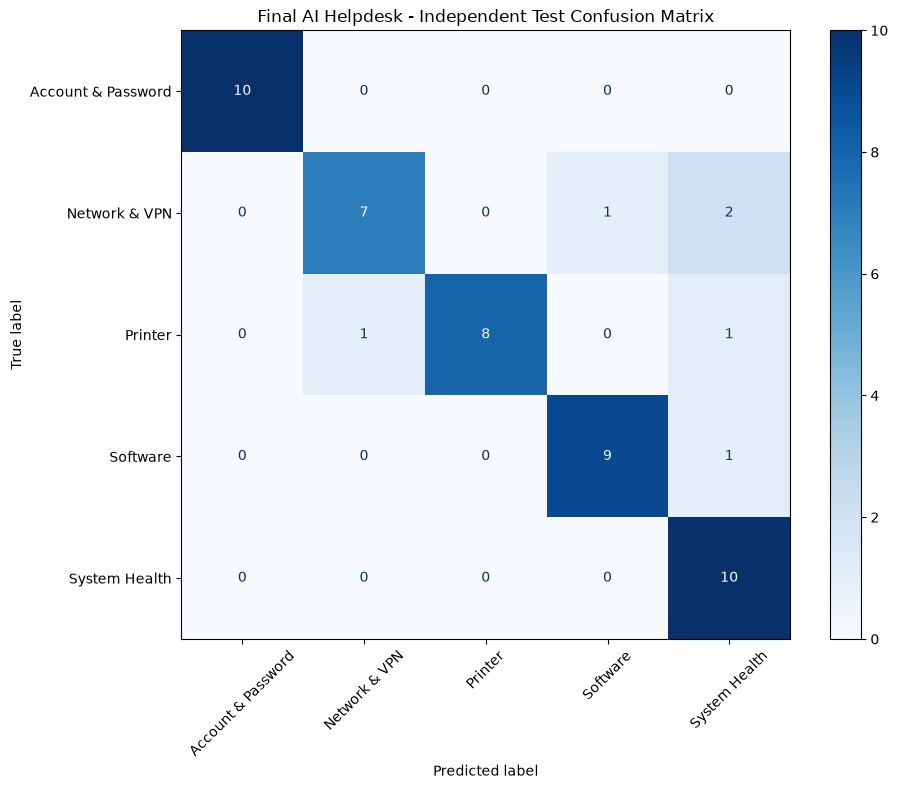


===== CATEGORY-WISE ACCURACY =====


,category,Accuracy_Percentage
0,Account & Password,100.0
1,Network & VPN,70.0
2,Printer,80.0
3,Software,90.0
4,System Health,100.0



Evaluation files saved successfully.
Predictions: D:\AI_IT_HELPDESK\results\final_independent_test_predictions.csv
Metrics: D:\AI_IT_HELPDESK\results\final_independent_test_metrics.csv


In [3]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v2.pkl"

TEST_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "expanded_classification_test_template.csv"
)

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load model and independent test dataset
model = joblib.load(MODEL_PATH)
test_df = pd.read_csv(TEST_PATH)

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"].astype(str)

# Predict categories
y_pred = model.predict(X_test)

# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)

macro_precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

macro_recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("===== FINAL INDEPENDENT TEST EVALUATION =====")
print("Test records:", len(test_df))
print(f"Accuracy       : {accuracy:.4f}")
print(f"Macro Precision: {macro_precision:.4f}")
print(f"Macro Recall   : {macro_recall:.4f}")
print(f"Macro F1-score : {macro_f1:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test, y_pred, zero_division=0
))

# Save individual predictions
prediction_df = test_df.copy()
prediction_df["predicted_category"] = y_pred
prediction_df["correct"] = (
    prediction_df["category"] == prediction_df["predicted_category"]
)

prediction_path = (
    RESULTS_DIR / "final_independent_test_predictions.csv"
)

prediction_df.to_csv(prediction_path, index=False)

# Confusion matrix
labels = sorted(set(y_test) | set(y_pred))

cm = confusion_matrix(
    y_test, y_pred, labels=labels
)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

fig, ax = plt.subplots(figsize=(10, 8))
display_cm.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d"
)

plt.title("Final AI Helpdesk - Independent Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "final_independent_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Category-wise accuracy
prediction_df["correct"] = prediction_df["correct"].astype(int)

category_accuracy = (
    prediction_df.groupby("category")["correct"]
    .mean()
    .mul(100)
    .reset_index(name="Accuracy_Percentage")
)

print("\n===== CATEGORY-WISE ACCURACY =====")
display(category_accuracy)

# Save evaluation summary
summary_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1"
    ],
    "Score": [
        accuracy,
        macro_precision,
        macro_recall,
        macro_f1
    ]
})

summary_df.to_csv(
    RESULTS_DIR / "final_independent_test_metrics.csv",
    index=False
)

print("\nEvaluation files saved successfully.")
print("Predictions:", prediction_path)
print("Metrics:", RESULTS_DIR / "final_independent_test_metrics.csv")


In [ ]:
#  Classification Error Analysis

In [4]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

PREDICTION_PATH = (
    BASE_DIR / "results" /
    "final_independent_test_predictions.csv"
)

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

df = pd.read_csv(PREDICTION_PATH)

# Extract incorrect predictions
errors = df[df["correct"] == False].copy()

print("===== CLASSIFICATION ERROR ANALYSIS =====")
print("Total test records:", len(df))
print("Correct predictions:", len(df) - len(errors))
print("Incorrect predictions:", len(errors))

print("\n===== INCORRECT PREDICTIONS =====")

display(
    errors[
        ["user_query", "category", "predicted_category"]
    ]
)

# Summarise category confusion
errors["error_type"] = (
    errors["category"].astype(str)
    + " -> "
    + errors["predicted_category"].astype(str)
)

error_summary = (
    errors["error_type"]
    .value_counts()
    .reset_index()
)

error_summary.columns = ["Error_Type", "Error_Count"]

print("\n===== ERROR SUMMARY =====")
display(error_summary)

# Save error analysis
errors.to_csv(
    RESULTS_DIR / "final_classification_errors.csv",
    index=False
)

error_summary.to_csv(
    RESULTS_DIR / "final_classification_error_summary.csv",
    index=False
)

print("\nError analysis saved successfully.")


===== CLASSIFICATION ERROR ANALYSIS =====
Total test records: 50
Correct predictions: 44
Incorrect predictions: 6

===== INCORRECT PREDICTIONS =====


,user_query,category,predicted_category
10,My computer is connected to WiFi but websites ...,Network & VPN,System Health
17,My computer is receiving an invalid IP address.,Network & VPN,System Health
19,I am getting a DNS server not responding error.,Network & VPN,Software
25,My computer cannot communicate with the networ...,Printer,Network & VPN
27,Print jobs are taking too long to complete.,Printer,System Health
39,The program reports that it has stopped working.,Software,System Health



===== ERROR SUMMARY =====


,Error_Type,Error_Count
0,Network & VPN -> System Health,2
1,Network & VPN -> Software,1
2,Printer -> Network & VPN,1
3,Printer -> System Health,1
4,Software -> System Health,1



Error analysis saved successfully.


In [ ]:
# Create additional training examples

In [5]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

OUTPUT_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "targeted_additional_training_data.csv"
)

new_data = [

    # NETWORK & VPN - 15 examples
    ("The office Wi-Fi connection keeps disconnecting.", "Network & VPN"),
    ("I cannot connect to the corporate VPN server.", "Network & VPN"),
    ("My computer cannot obtain an IP address from DHCP.", "Network & VPN"),
    ("The DNS lookup failed when accessing company websites.", "Network & VPN"),
    ("The network adapter shows no internet connectivity.", "Network & VPN"),
    ("I receive a network gateway unreachable error.", "Network & VPN"),
    ("The VPN client fails during authentication.", "Network & VPN"),
    ("My laptop cannot connect to the office LAN.", "Network & VPN"),
    ("The network connection is limited or unavailable.", "Network & VPN"),
    ("I cannot access shared network folders because of connectivity.", "Network & VPN"),
    ("The computer reports a duplicate IP address on the network.", "Network & VPN"),
    ("The VPN tunnel disconnects repeatedly during work.", "Network & VPN"),
    ("The network cable is connected but there is no network access.", "Network & VPN"),
    ("The computer cannot resolve internal DNS hostnames.", "Network & VPN"),
    ("I cannot reach the company intranet through the network.", "Network & VPN"),

    # PRINTER - 10 examples
    ("The office printer does not respond to print commands.", "Printer"),
    ("My documents remain stuck in the printer queue.", "Printer"),
    ("Windows cannot detect the connected office printer.", "Printer"),
    ("The printer displays a paper jam warning.", "Printer"),
    ("The printer driver installation has failed.", "Printer"),
    ("The printer produces blank pages when printing.", "Printer"),
    ("I cannot select the network printer from Microsoft Word.", "Printer"),
    ("The printer status shows paused instead of ready.", "Printer"),
    ("The printer is displaying an offline status in Windows.", "Printer"),
    ("Print jobs are failing because the printer spooler stopped.", "Printer"),

    # SYSTEM HEALTH - 5 examples
    ("My computer takes a long time to start Windows.", "System Health"),
    ("The laptop becomes unresponsive because memory usage is high.", "System Health"),
    ("Windows frequently freezes during normal operation.", "System Health"),
    ("The computer has insufficient disk space on its system drive.", "System Health"),
    ("The operating system restarts unexpectedly during use.", "System Health")
]

additional_df = pd.DataFrame(
    new_data,
    columns=["user_query", "category"]
)

additional_df.insert(
    0,
    "Training_ID",
    [f"TARGET{i:03d}" for i in range(1, len(additional_df) + 1)]
)

additional_df.to_csv(OUTPUT_PATH, index=False)

print("Additional training dataset created.")
print("Total new records:", len(additional_df))

print("\nCategory distribution:")
print(additional_df["category"].value_counts())

print("\nMissing values:")
print(additional_df.isnull().sum())

print("\nSaved to:", OUTPUT_PATH)

display(additional_df)


Additional training dataset created.
Total new records: 30

Category distribution:
category
Network & VPN    15
Printer          10
System Health     5
Name: count, dtype: int64

Missing values:
Training_ID    0
user_query     0
category       0
dtype: int64

Saved to: D:\AI_IT_HELPDESK\dataset\processed\targeted_additional_training_data.csv


,Training_ID,user_query,category
0,TARGET001,The office Wi-Fi connection keeps disconnecting.,Network & VPN
1,TARGET002,I cannot connect to the corporate VPN server.,Network & VPN
2,TARGET003,My computer cannot obtain an IP address from D...,Network & VPN
3,TARGET004,The DNS lookup failed when accessing company w...,Network & VPN
4,TARGET005,The network adapter shows no internet connecti...,Network & VPN
5,TARGET006,I receive a network gateway unreachable error.,Network & VPN
6,TARGET007,The VPN client fails during authentication.,Network & VPN
7,TARGET008,My laptop cannot connect to the office LAN.,Network & VPN
8,TARGET009,The network connection is limited or unavailable.,Network & VPN
9,TARGET010,I cannot access shared network folders because...,Network & VPN


In [ ]:
# Validate and merge training data

In [6]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

ORIGINAL_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "improved_training_dataset.csv"
)

ADDITIONAL_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "targeted_additional_training_data.csv"
)

MERGED_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "improved_training_dataset_v2.csv"
)

original_df = pd.read_csv(ORIGINAL_PATH)
additional_df = pd.read_csv(ADDITIONAL_PATH)

# Keep only the model's required columns
original_df = original_df[["user_query", "category"]]
additional_df = additional_df[["user_query", "category"]]

# Normalise text for duplicate detection
original_queries = set(
    original_df["user_query"].str.strip().str.lower()
)

additional_queries = (
    additional_df["user_query"].str.strip().str.lower()
)

duplicate_count = additional_queries.isin(original_queries).sum()

# Merge and remove exact duplicate queries
merged_df = pd.concat(
    [original_df, additional_df],
    ignore_index=True
)

merged_df["_normalised_query"] = (
    merged_df["user_query"].str.strip().str.lower()
)

merged_df = merged_df.drop_duplicates(
    subset=["_normalised_query"],
    keep="first"
).drop(columns=["_normalised_query"])

merged_df.to_csv(MERGED_PATH, index=False)

print("===== DATASET MERGE SUMMARY =====")
print("Original records:", len(original_df))
print("Additional records:", len(additional_df))
print("Duplicate additional queries:", duplicate_count)
print("Final unique records:", len(merged_df))

print("\nCategory distribution:")
print(merged_df["category"].value_counts())

print("\nMissing values:")
print(merged_df.isnull().sum())

print("\nSaved to:", MERGED_PATH)


===== DATASET MERGE SUMMARY =====
Original records: 135
Additional records: 30
Duplicate additional queries: 1
Final unique records: 164

Category distribution:
category
Network & VPN         41
Printer               37
System Health         32
Account & Password    27
Software              27
Name: count, dtype: int64

Missing values:
user_query    0
category      0
dtype: int64

Saved to: D:\AI_IT_HELPDESK\dataset\processed\improved_training_dataset_v2.csv


In [ ]:
#  Dataset quality validation

In [7]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

DATA_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "improved_training_dataset_v2.csv"
)

df = pd.read_csv(DATA_PATH)

df["normalised_query"] = (
    df["user_query"].astype(str).str.strip().str.lower()
)

# Find queries appearing more than once
duplicates = df[
    df.duplicated("normalised_query", keep=False)
].sort_values("normalised_query")

# Identify queries with conflicting labels
conflicts = (
    df.groupby("normalised_query")["category"]
    .nunique()
)

conflicts = conflicts[conflicts > 1]

print("===== DATA QUALITY VALIDATION =====")
print("Total records:", len(df))
print("Duplicate query rows:", len(duplicates))
print("Conflicting category labels:", len(conflicts))
print("Missing values:")
print(df[["user_query", "category"]].isnull().sum())

if len(conflicts) > 0:
    print("\nWARNING: Conflicting labels found.")
    display(
        df[df["normalised_query"].isin(conflicts.index)]
        [["user_query", "category"]]
    )
else:
    print("\nNo conflicting category labels found.")

print("\nCategory distribution:")
print(df["category"].value_counts())

df.drop(columns=["normalised_query"], inplace=True)


===== DATA QUALITY VALIDATION =====
Total records: 164
Duplicate query rows: 0
Conflicting category labels: 0
Missing values:
user_query    0
category      0
dtype: int64

No conflicting category labels found.

Category distribution:
category
Network & VPN         41
Printer               37
System Health         32
Account & Password    27
Software              27
Name: count, dtype: int64


In [ ]:
# Compare models using 5-fold cross-validation

In [8]:
import pandas as pd
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_validate

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

DATA_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "improved_training_dataset_v2.csv"
)

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

X = df["user_query"].astype(str)
y = df["category"].astype(str)

# Stratified five-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=10000,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Linear SVM": Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=10000,
            sublinear_tf=True
        )),
        ("classifier", LinearSVC(
            class_weight="balanced",
            random_state=42
        ))
    ])
}

scoring = {
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro"
}

results = []

for model_name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    results.append({
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Accuracy_STD": scores["test_accuracy"].std(),
        "Macro_Precision": scores["test_precision_macro"].mean(),
        "Macro_Recall": scores["test_recall_macro"].mean(),
        "Macro_F1": scores["test_f1_macro"].mean(),
        "F1_STD": scores["test_f1_macro"].std()
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    "Macro_F1",
    ascending=False
)

print("===== 5-FOLD CROSS-VALIDATION RESULTS =====")
display(comparison_df)

output_path = (
    RESULTS_DIR / "model_comparison_5fold_v3.csv"
)

comparison_df.to_csv(output_path, index=False)

print("\nResults saved to:", output_path)


===== 5-FOLD CROSS-VALIDATION RESULTS =====


,Model,Accuracy,Accuracy_STD,Macro_Precision,Macro_Recall,Macro_F1,F1_STD
1,Linear SVM,0.963068,0.030738,0.969632,0.959238,0.960117,0.033008
0,Logistic Regression,0.944508,0.053901,0.951349,0.942349,0.941872,0.053854



Results saved to: D:\AI_IT_HELPDESK\results\model_comparison_5fold_v3.csv


In [ ]:
# Train calibrated Linear SVM V3

In [9]:
import pandas as pd
import joblib

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

DATA_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "improved_training_dataset_v2.csv"
)

MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "it_helpdesk_classifier_v3.pkl"

# Load dataset
df = pd.read_csv(DATA_PATH)

X = df["user_query"].astype(str)
y = df["category"].astype(str)

# Base TF-IDF + Linear SVM pipeline
base_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=10000,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LinearSVC(
            class_weight="balanced",
            random_state=42
        )
    )
])

# Calibrate SVM probabilities using internal CV
try:
    calibrated_model = CalibratedClassifierCV(
        estimator=base_pipeline,
        method="sigmoid",
        cv=5
    )
except TypeError:
    # Compatibility with older scikit-learn versions
    calibrated_model = CalibratedClassifierCV(
        base_estimator=base_pipeline,
        method="sigmoid",
        cv=5
    )

# Train calibrated model on all 164 records
calibrated_model.fit(X, y)

# Save model
joblib.dump(calibrated_model, MODEL_PATH)

# Reload and verify
loaded_model = joblib.load(MODEL_PATH)

print("===== FINAL V3 MODEL TRAINING =====")
print("Training records:", len(df))
print("Model: Calibrated Linear SVM")
print("Model saved:", MODEL_PATH)
print("Model exists:", MODEL_PATH.exists())
print("Supports predict:", hasattr(loaded_model, "predict"))
print(
    "Supports predict_proba:",
    hasattr(loaded_model, "predict_proba")
)
print("Categories:", loaded_model.classes_)


===== FINAL V3 MODEL TRAINING =====
Training records: 164
Model: Calibrated Linear SVM
Model saved: D:\AI_IT_HELPDESK\models\it_helpdesk_classifier_v3.pkl
Model exists: True
Supports predict: True
Supports predict_proba: True
Categories: ['Account & Password' 'Network & VPN' 'Printer' 'Software' 'System Health']


In [ ]:
# Verify V3 predictions

In [10]:
test_queries = [
    "My office Wi-Fi keeps disconnecting.",
    "My network printer is offline.",
    "I cannot reset my Windows password.",
    "My laptop is running very slowly.",
    "My VPN connection keeps failing."
]

loaded_model = joblib.load(MODEL_PATH)

predictions = loaded_model.predict(test_queries)
probabilities = loaded_model.predict_proba(test_queries)

test_results = pd.DataFrame({
    "User_Query": test_queries,
    "Predicted_Category": predictions,
    "Confidence_Percentage": (
        probabilities.max(axis=1) * 100
    ).round(2)
})

print("===== V3 MODEL PREDICTION TEST =====")
display(test_results)


===== V3 MODEL PREDICTION TEST =====


,User_Query,Predicted_Category,Confidence_Percentage
0,My office Wi-Fi keeps disconnecting.,Network & VPN,62.60
1,My network printer is offline.,Printer,88.80
2,I cannot reset my Windows password.,Account & Password,86.50
3,My laptop is running very slowly.,System Health,85.52
4,My VPN connection keeps failing.,Network & VPN,83.90


In [ ]:
#  Backup existing Streamlit application

In [11]:
import shutil
from pathlib import Path
from datetime import datetime

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

APP_PATH = BASE_DIR / "frontend" / "app.py"
BACKUP_DIR = BASE_DIR / "frontend" / "backups"

BACKUP_DIR.mkdir(parents=True, exist_ok=True)

if not APP_PATH.exists():
    raise FileNotFoundError(f"Application not found: {APP_PATH}")

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

BACKUP_PATH = (
    BACKUP_DIR / f"app_backup_{timestamp}.py"
)

shutil.copy2(APP_PATH, BACKUP_PATH)

print("Application backup completed.")
print("Original:", APP_PATH)
print("Backup:", BACKUP_PATH)
print("Backup exists:", BACKUP_PATH.exists())


Application backup completed.
Original: D:\AI_IT_HELPDESK\frontend\app.py
Backup: D:\AI_IT_HELPDESK\frontend\backups\app_backup_20261103_164914.py
Backup exists: True


In [ ]:
# Inspect current AI model integration

In [12]:
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

APP_PATH = BASE_DIR / "frontend" / "app.py"

with open(APP_PATH, "r", encoding="utf-8") as file:
    app_code = file.readlines()

keywords = [
    "MODEL_PATH",
    "it_helpdesk_classifier",
    "joblib.load",
    "def classify_issue",
    "predict_proba",
    "predict("
]

for line_number, line in enumerate(app_code, start=1):
    if any(keyword in line for keyword in keywords):
        print(f"Line {line_number}: {line.rstrip()}")


Line 20: MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier.pkl"
Line 564:     classifier = joblib.load(MODEL_PATH)
Line 589: def classify_issue(query):
Line 591:     category = classifier.predict([query])[0]
Line 595:     if hasattr(classifier, "predict_proba"):
Line 597:         probabilities = classifier.predict_proba([query])[0]


In [ ]:
#  Safely update Streamlit model path

In [13]:
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

APP_PATH = BASE_DIR / "frontend" / "app.py"

OLD_TEXT = 'MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier.pkl"'

NEW_TEXT = 'MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v3.pkl"'

# Read application
app_code = APP_PATH.read_text(encoding="utf-8")

# Confirm the old model path exists exactly once
count = app_code.count(OLD_TEXT)

if count != 1:
    raise ValueError(
        f"Expected exactly one old model path, found: {count}. "
        "No changes were made."
    )

# Verify V3 model exists
MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v3.pkl"

if not MODEL_PATH.exists():
    raise FileNotFoundError(MODEL_PATH)

# Replace only the model path
updated_code = app_code.replace(OLD_TEXT, NEW_TEXT, 1)

# Save updated application
APP_PATH.write_text(updated_code, encoding="utf-8")

# Verify
saved_code = APP_PATH.read_text(encoding="utf-8")

print("Streamlit application updated successfully.")
print("V3 model exists:", MODEL_PATH.exists())
print("Old model path remaining:", OLD_TEXT in saved_code)
print("New model path found:", NEW_TEXT in saved_code)


Streamlit application updated successfully.
V3 model exists: True
Old model path remaining: False
New model path found: True


In [ ]:
#  Restart Streamlit application

In [14]:
from pathlib import Path
import subprocess
import sys

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

APP_PATH = BASE_DIR / "frontend" / "app.py"

process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        str(APP_PATH),
        "--server.port=8501"
    ],
    cwd=str(APP_PATH.parent)
)

print("AI Helpdesk application started.")
print("URL: http://localhost:8501")
print("Process ID:", process.pid)


AI Helpdesk application started.
URL: http://localhost:8501
Process ID: 17660


In [ ]:
# Check evaluation files

In [15]:
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

V2_MODEL = BASE_DIR / "models" / "it_helpdesk_classifier_v2.pkl"
V3_MODEL = BASE_DIR / "models" / "it_helpdesk_classifier_v3.pkl"

TEST_DATA = (
    BASE_DIR / "dataset" / "processed"
    / "expanded_classification_test_template.csv"
)

files = {
    "V2 Model": V2_MODEL,
    "V3 Model": V3_MODEL,
    "Independent Test Dataset": TEST_DATA
}

for name, path in files.items():
    print(f"{name}: {path.exists()}")
    print(f"Path: {path}")
    print("-" * 60)


V2 Model: True
Path: D:\AI_IT_HELPDESK\models\it_helpdesk_classifier_v2.pkl
------------------------------------------------------------
V3 Model: True
Path: D:\AI_IT_HELPDESK\models\it_helpdesk_classifier_v3.pkl
------------------------------------------------------------
Independent Test Dataset: True
Path: D:\AI_IT_HELPDESK\dataset\processed\expanded_classification_test_template.csv
------------------------------------------------------------


In [ ]:
#  Load models and independent test data

In [16]:

import joblib
import pandas as pd

model_v2 = joblib.load(V2_MODEL)
model_v3 = joblib.load(V3_MODEL)

test_df = pd.read_csv(TEST_DATA)

print("V2 model loaded:", type(model_v2))
print("V3 model loaded:", type(model_v3))

print("\nTest dataset shape:", test_df.shape)
print("\nDataset columns:", test_df.columns.tolist())

display(test_df.head())


V2 model loaded: <class 'sklearn.pipeline.Pipeline'>
V3 model loaded: <class 'sklearn.calibration.CalibratedClassifierCV'>

Test dataset shape: (50, 3)

Dataset columns: ['Test_ID', 'user_query', 'category']


,Test_ID,user_query,category
0,EXT001,I cannot remember my Windows login password.,Account & Password
1,EXT002,My domain account says the password has expired.,Account & Password
2,EXT003,My account is locked after several failed logi...,Account & Password
3,EXT004,I cannot sign in to my computer using my domai...,Account & Password
4,EXT005,How can I change my current Windows password?,Account & Password


In [ ]:
#  Comparative model evaluation

In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Validate test data
required_columns = ["user_query", "category"]

if not all(col in test_df.columns for col in required_columns):
    raise ValueError("Required test dataset columns are missing.")

if test_df[required_columns].isnull().any().any():
    raise ValueError("Missing values found in test dataset.")

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"].astype(str)

# Generate predictions
pred_v2 = model_v2.predict(X_test)
pred_v3 = model_v3.predict(X_test)

# Calculate metrics
results = []

for model_name, predictions in [
    ("V2 - Previous Model", pred_v2),
    ("V3 - Calibrated Linear SVM", pred_v3)
]:
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

print("===== V2 vs V3 COMPARISON =====")
display(comparison_df.round(4))

# Detailed reports
print("\n===== V2 CLASSIFICATION REPORT =====")
print(classification_report(y_test, pred_v2, zero_division=0))

print("\n===== V3 CLASSIFICATION REPORT =====")
print(classification_report(y_test, pred_v3, zero_division=0))


===== V2 vs V3 COMPARISON =====


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,V2 - Previous Model,0.88,0.8979,0.88,0.8800
1,V3 - Calibrated Linear SVM,0.90,0.9022,0.90,0.8987



===== V2 CLASSIFICATION REPORT =====
                    precision    recall  f1-score   support

Account & Password       1.00      1.00      1.00        10
     Network & VPN       0.88      0.70      0.78        10
           Printer       1.00      0.80      0.89        10
          Software       0.90      0.90      0.90        10
     System Health       0.71      1.00      0.83        10

          accuracy                           0.88        50
         macro avg       0.90      0.88      0.88        50
      weighted avg       0.90      0.88      0.88        50


===== V3 CLASSIFICATION REPORT =====
                    precision    recall  f1-score   support

Account & Password       1.00      1.00      1.00        10
     Network & VPN       0.89      0.80      0.84        10
           Printer       0.89      0.80      0.84        10
          Software       0.90      0.90      0.90        10
     System Health       0.83      1.00      0.91        10

          accuracy 

In [ ]:
#  Confusion matrix comparison

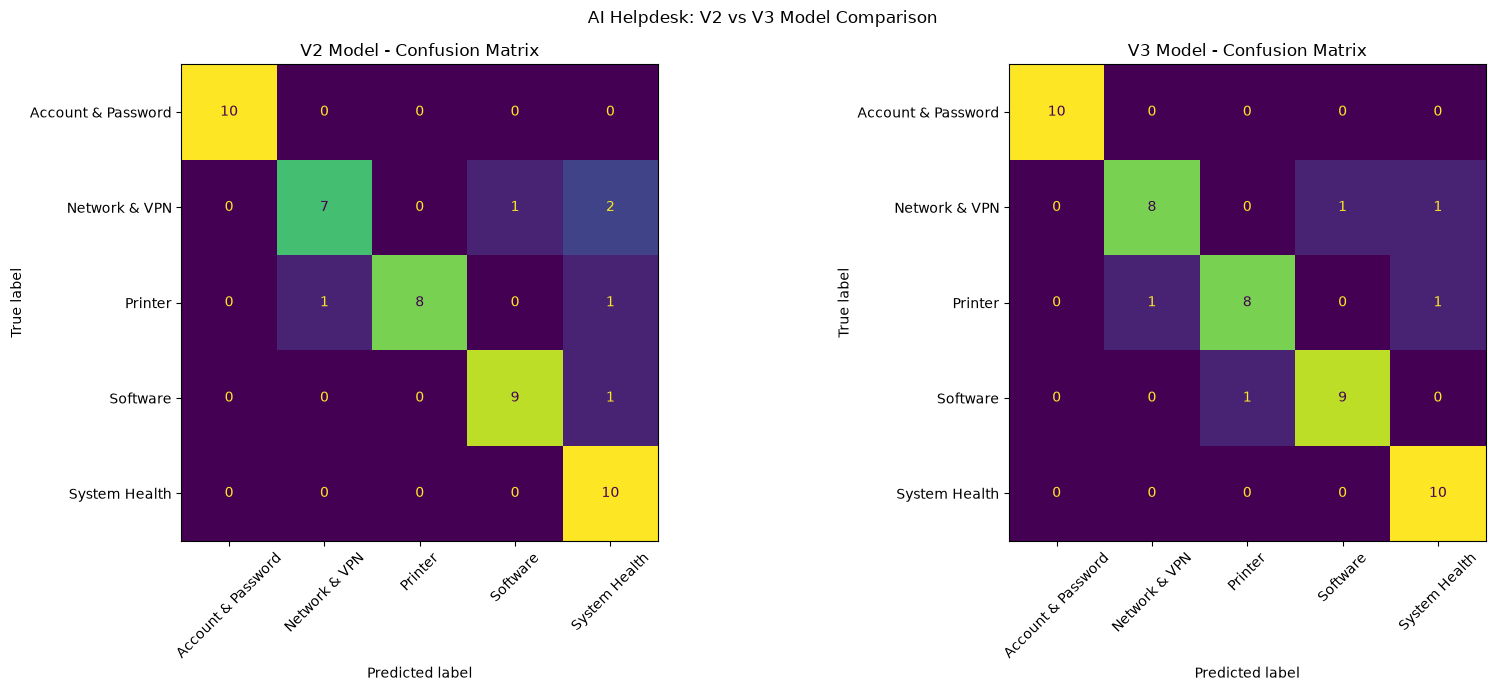

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

labels = sorted(y_test.unique())

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_v2,
    labels=labels,
    xticks_rotation=45,
    ax=axes[0],
    colorbar=False
)

axes[0].set_title("V2 Model - Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred_v3,
    labels=labels,
    xticks_rotation=45,
    ax=axes[1],
    colorbar=False
)

axes[1].set_title("V3 Model - Confusion Matrix")

plt.suptitle("AI Helpdesk: V2 vs V3 Model Comparison")
plt.tight_layout()
plt.show()


In [ ]:
# Calculate V3 improvement

In [19]:
v2_accuracy = comparison_df.loc[0, "Accuracy"]
v3_accuracy = comparison_df.loc[1, "Accuracy"]

v2_f1 = comparison_df.loc[0, "Macro F1"]
v3_f1 = comparison_df.loc[1, "Macro F1"]

print("===== MODEL IMPROVEMENT ANALYSIS =====")

print(f"V2 Accuracy: {v2_accuracy:.2%}")
print(f"V3 Accuracy: {v3_accuracy:.2%}")

print(f"\nAccuracy change: {(v3_accuracy-v2_accuracy)*100:.2f} percentage points")

print(f"\nV2 Macro F1: {v2_f1:.4f}")
print(f"V3 Macro F1: {v3_f1:.4f}")

print(f"Macro F1 change: {(v3_f1-v2_f1)*100:.2f} percentage points")

if v3_accuracy > v2_accuracy:
    print("\nV3 achieved higher test accuracy.")
elif v3_accuracy < v2_accuracy:
    print("\nV2 achieved higher test accuracy.")
else:
    print("\nBoth models achieved equal test accuracy.")


===== MODEL IMPROVEMENT ANALYSIS =====
V2 Accuracy: 88.00%
V3 Accuracy: 90.00%

Accuracy change: 2.00 percentage points

V2 Macro F1: 0.8800
V3 Macro F1: 0.8987
Macro F1 change: 1.87 percentage points

V3 achieved higher test accuracy.


In [ ]:
# Save comparison and prediction results


In [20]:

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save metrics
comparison_path = RESULTS_DIR / "v2_v3_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

# Save individual predictions
predictions_df = test_df.copy()

predictions_df["V2_Prediction"] = pred_v2
predictions_df["V3_Prediction"] = pred_v3

predictions_df["V2_Correct"] = (
    predictions_df["category"] == predictions_df["V2_Prediction"]
)

predictions_df["V3_Correct"] = (
    predictions_df["category"] == predictions_df["V3_Prediction"]
)

predictions_path = RESULTS_DIR / "v2_v3_test_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

print("Comparative evaluation saved successfully.")
print("Metrics:", comparison_path)
print("Predictions:", predictions_path)

display(predictions_df.head(10))


Comparative evaluation saved successfully.
Metrics: D:\AI_IT_HELPDESK\results\v2_v3_comparison.csv
Predictions: D:\AI_IT_HELPDESK\results\v2_v3_test_predictions.csv


,Test_ID,user_query,category,V2_Prediction,V3_Prediction,V2_Correct,V3_Correct
0,EXT001,I cannot remember my Windows login password.,Account & Password,Account & Password,Account & Password,True,True
1,EXT002,My domain account says the password has expired.,Account & Password,Account & Password,Account & Password,True,True
2,EXT003,My account is locked after several failed logi...,Account & Password,Account & Password,Account & Password,True,True
3,EXT004,I cannot sign in to my computer using my domai...,Account & Password,Account & Password,Account & Password,True,True
4,EXT005,How can I change my current Windows password?,Account & Password,Account & Password,Account & Password,True,True
5,EXT006,My username and password are not being accepted.,Account & Password,Account & Password,Account & Password,True,True
6,EXT007,I need assistance resetting my Microsoft 365 p...,Account & Password,Account & Password,Account & Password,True,True
7,EXT008,My account has been disabled and I cannot log in.,Account & Password,Account & Password,Account & Password,True,True
8,EXT009,I can log in to Windows but cannot access my w...,Account & Password,Account & Password,Account & Password,True,True
9,EXT010,I am getting an authentication error when sign...,Account & Password,Account & Password,Account & Password,True,True


In [ ]:
#  Load saved V2 vs V3 predictions


In [21]:
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

PREDICTIONS_PATH = (
    BASE_DIR / "results" / "v2_v3_test_predictions.csv"
)

predictions_df = pd.read_csv(PREDICTIONS_PATH)

required_columns = [
    "Test_ID",
    "user_query",
    "category",
    "V2_Prediction",
    "V3_Prediction",
    "V2_Correct",
    "V3_Correct"
]

missing = [
    col for col in required_columns
    if col not in predictions_df.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

print("Total test records:", len(predictions_df))
print("\nLoaded columns:")
print(predictions_df.columns.tolist())

display(predictions_df.head())


Total test records: 50

Loaded columns:
['Test_ID', 'user_query', 'category', 'V2_Prediction', 'V3_Prediction', 'V2_Correct', 'V3_Correct']


,Test_ID,user_query,category,V2_Prediction,V3_Prediction,V2_Correct,V3_Correct
0,EXT001,I cannot remember my Windows login password.,Account & Password,Account & Password,Account & Password,True,True
1,EXT002,My domain account says the password has expired.,Account & Password,Account & Password,Account & Password,True,True
2,EXT003,My account is locked after several failed logi...,Account & Password,Account & Password,Account & Password,True,True
3,EXT004,I cannot sign in to my computer using my domai...,Account & Password,Account & Password,Account & Password,True,True
4,EXT005,How can I change my current Windows password?,Account & Password,Account & Password,Account & Password,True,True


In [ ]:
#  Compare prediction changes

In [22]:
# Convert CSV Boolean values safely
for col in ["V2_Correct", "V3_Correct"]:
    predictions_df[col] = (
        predictions_df[col].astype(str).str.lower() == "true"
    )

# V2 incorrect, V3 correct
corrected_by_v3 = predictions_df[
    (~predictions_df["V2_Correct"]) &
    (predictions_df["V3_Correct"])
]

# V2 correct, V3 incorrect
regressed_by_v3 = predictions_df[
    (predictions_df["V2_Correct"]) &
    (~predictions_df["V3_Correct"])
]

# Both models incorrect
both_incorrect = predictions_df[
    (~predictions_df["V2_Correct"]) &
    (~predictions_df["V3_Correct"])
]

print("===== PREDICTION CHANGE ANALYSIS =====")

print("Corrected by V3:", len(corrected_by_v3))
print("New errors introduced by V3:", len(regressed_by_v3))
print("Incorrect in both models:", len(both_incorrect))

print("\n===== CORRECTED BY V3 =====")
display(corrected_by_v3)

print("\n===== NEW ERRORS IN V3 =====")
display(regressed_by_v3)

print("\n===== ERRORS IN BOTH MODELS =====")
display(both_incorrect)


===== PREDICTION CHANGE ANALYSIS =====
Corrected by V3: 1
New errors introduced by V3: 0
Incorrect in both models: 5

===== CORRECTED BY V3 =====


,Test_ID,user_query,category,V2_Prediction,V3_Prediction,V2_Correct,V3_Correct
10,EXT011,My computer is connected to WiFi but websites ...,Network & VPN,System Health,Network & VPN,False,True



===== NEW ERRORS IN V3 =====


,Test_ID,user_query,category,V2_Prediction,V3_Prediction,V2_Correct,V3_Correct



===== ERRORS IN BOTH MODELS =====


,Test_ID,user_query,category,V2_Prediction,V3_Prediction,V2_Correct,V3_Correct
17,EXT018,My computer is receiving an invalid IP address.,Network & VPN,System Health,System Health,False,False
19,EXT020,I am getting a DNS server not responding error.,Network & VPN,Software,Software,False,False
25,EXT026,My computer cannot communicate with the networ...,Printer,Network & VPN,Network & VPN,False,False
27,EXT028,Print jobs are taking too long to complete.,Printer,System Health,System Health,False,False
39,EXT040,The program reports that it has stopped working.,Software,System Health,Printer,False,False


In [ ]:
#  V3 error analysis

In [23]:
v3_errors = predictions_df[
    ~predictions_df["V3_Correct"]
].copy()

v3_errors["Error_Type"] = (
    v3_errors["category"].astype(str)
    + " -> "
    + v3_errors["V3_Prediction"].astype(str)
)

error_summary = (
    v3_errors.groupby("Error_Type")
    .size()
    .reset_index(name="Error_Count")
    .sort_values("Error_Count", ascending=False)
)

print("===== V3 CLASSIFICATION ERROR SUMMARY =====")
print("Total test records:", len(predictions_df))
print("Correct predictions:", int(predictions_df["V3_Correct"].sum()))
print("Incorrect predictions:", len(v3_errors))

display(error_summary)

print("\n===== V3 INCORRECT PREDICTIONS =====")

display(
    v3_errors[
        ["Test_ID", "user_query", "category", "V3_Prediction"]
    ]
)


===== V3 CLASSIFICATION ERROR SUMMARY =====
Total test records: 50
Correct predictions: 45
Incorrect predictions: 5


,Error_Type,Error_Count
0,Network & VPN -> Software,1
1,Network & VPN -> System Health,1
2,Printer -> Network & VPN,1
3,Printer -> System Health,1
4,Software -> Printer,1



===== V3 INCORRECT PREDICTIONS =====


,Test_ID,user_query,category,V3_Prediction
17,EXT018,My computer is receiving an invalid IP address.,Network & VPN,System Health
19,EXT020,I am getting a DNS server not responding error.,Network & VPN,Software
25,EXT026,My computer cannot communicate with the networ...,Printer,Network & VPN
27,EXT028,Print jobs are taking too long to complete.,Printer,System Health
39,EXT040,The program reports that it has stopped working.,Software,Printer


In [ ]:
#  Save error analysis reports

In [24]:
RESULTS_DIR = BASE_DIR / "results"

corrected_by_v3.to_csv(
    RESULTS_DIR / "v3_corrected_predictions.csv",
    index=False
)

regressed_by_v3.to_csv(
    RESULTS_DIR / "v3_new_errors.csv",
    index=False
)

v3_errors.to_csv(
    RESULTS_DIR / "v3_classification_errors.csv",
    index=False
)

error_summary.to_csv(
    RESULTS_DIR / "v3_error_summary.csv",
    index=False
)

print("STEP 32.16 COMPLETED")
print("Corrected predictions saved.")
print("New errors saved.")
print("V3 error details saved.")
print("Error summary saved.")


STEP 32.16 COMPLETED
Corrected predictions saved.
New errors saved.
V3 error details saved.
Error summary saved.


In [ ]:
# Load V3 model and test dataset

In [25]:
from pathlib import Path
import joblib
import pandas as pd
import numpy as np

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v3.pkl"
TEST_PATH = (
    BASE_DIR / "dataset" / "processed"
    / "expanded_classification_test_template.csv"
)

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

classifier_v3 = joblib.load(MODEL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("V3 model loaded:", type(classifier_v3))
print("Test records:", len(test_df))
print("Probability support:", hasattr(classifier_v3, "predict_proba"))

if not hasattr(classifier_v3, "predict_proba"):
    raise RuntimeError("V3 model does not support predict_proba().")

if test_df[["user_query", "category"]].isnull().any().any():
    raise ValueError("Missing test data detected.")

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"].astype(str)

print("\nAvailable categories:")
print(classifier_v3.classes_)


V3 model loaded: <class 'sklearn.calibration.CalibratedClassifierCV'>
Test records: 50
Probability support: True

Available categories:
['Account & Password' 'Network & VPN' 'Printer' 'Software' 'System Health']


In [ ]:
# Generate prediction confidence

In [26]:
probabilities = classifier_v3.predict_proba(X_test)

predicted_indices = np.argmax(probabilities, axis=1)

predicted_categories = classifier_v3.classes_[predicted_indices]

confidence_scores = np.max(probabilities, axis=1)

confidence_df = test_df.copy()

confidence_df["Predicted_Category"] = predicted_categories

confidence_df["Confidence"] = confidence_scores

confidence_df["Confidence_Percentage"] = (
    confidence_scores * 100
).round(2)

confidence_df["Correct"] = (
    confidence_df["category"] ==
    confidence_df["Predicted_Category"]
)

print("===== CONFIDENCE PREDICTION RESULTS =====")

display(
    confidence_df[
        [
            "Test_ID",
            "user_query",
            "category",
            "Predicted_Category",
            "Confidence_Percentage",
            "Correct"
        ]
    ].head(15)
)

print("\nAverage confidence:",
      f"{confidence_scores.mean() * 100:.2f}%")

print("Minimum confidence:",
      f"{confidence_scores.min() * 100:.2f}%")

print("Maximum confidence:",
      f"{confidence_scores.max() * 100:.2f}%")


===== CONFIDENCE PREDICTION RESULTS =====


,Test_ID,user_query,category,Predicted_Category,Confidence_Percentage,Correct
0,EXT001,I cannot remember my Windows login password.,Account & Password,Account & Password,88.25,True
1,EXT002,My domain account says the password has expired.,Account & Password,Account & Password,88.45,True
2,EXT003,My account is locked after several failed logi...,Account & Password,Account & Password,85.93,True
3,EXT004,I cannot sign in to my computer using my domai...,Account & Password,Account & Password,87.11,True
4,EXT005,How can I change my current Windows password?,Account & Password,Account & Password,80.97,True
5,EXT006,My username and password are not being accepted.,Account & Password,Account & Password,79.89,True
6,EXT007,I need assistance resetting my Microsoft 365 p...,Account & Password,Account & Password,80.38,True
7,EXT008,My account has been disabled and I cannot log in.,Account & Password,Account & Password,87.95,True
8,EXT009,I can log in to Windows but cannot access my w...,Account & Password,Account & Password,85.89,True
9,EXT010,I am getting an authentication error when sign...,Account & Password,Account & Password,44.39,True



Average confidence: 76.78%
Minimum confidence: 32.28%
Maximum confidence: 91.86%


In [ ]:
#  Confidence distribution

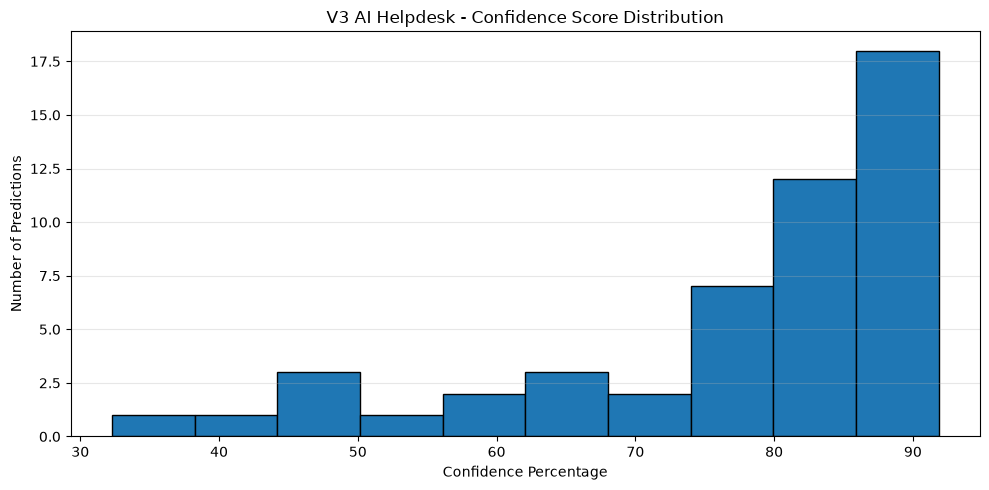

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    confidence_scores * 100,
    bins=10,
    edgecolor="black"
)

plt.title("V3 AI Helpdesk - Confidence Score Distribution")
plt.xlabel("Confidence Percentage")
plt.ylabel("Number of Predictions")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
#  Confidence and correctness analysis

In [28]:
confidence_df["Confidence_Band"] = pd.cut(
    confidence_df["Confidence"],
    bins=[0, 0.50, 0.60, 0.70, 0.80, 0.90, 1.01],
    labels=[
        "0-50%",
        "50-60%",
        "60-70%",
        "70-80%",
        "80-90%",
        "90-100%"
    ],
    include_lowest=True
)

confidence_analysis = (
    confidence_df.groupby(
        "Confidence_Band",
        observed=False
    )
    .agg(
        Total_Predictions=("Correct", "count"),
        Correct_Predictions=("Correct", "sum"),
        Actual_Accuracy=("Correct", "mean"),
        Average_Confidence=("Confidence", "mean")
    )
    .reset_index()
)

confidence_analysis["Actual_Accuracy"] *= 100
confidence_analysis["Average_Confidence"] *= 100

print("===== CONFIDENCE RELIABILITY ANALYSIS =====")

display(confidence_analysis.round(2))


===== CONFIDENCE RELIABILITY ANALYSIS =====


,Confidence_Band,Total_Predictions,Correct_Predictions,Actual_Accuracy,Average_Confidence
0,0-50%,5,2,40.0,41.87
1,50-60%,2,2,100.0,57.60
2,60-70%,5,3,60.0,64.23
3,70-80%,8,8,100.0,76.73
4,80-90%,27,27,100.0,85.43
5,90-100%,3,3,100.0,90.90


In [ ]:
# Confidence threshold analysis

In [29]:

thresholds = [0.60, 0.70, 0.80]

threshold_results = []

for threshold in thresholds:

    accepted = confidence_df[
        confidence_df["Confidence"] >= threshold
    ]

    rejected = confidence_df[
        confidence_df["Confidence"] < threshold
    ]

    accepted_accuracy = (
        accepted["Correct"].mean() * 100
        if len(accepted) > 0 else 0
    )

    threshold_results.append({
        "Threshold": f"{threshold:.0%}",
        "Accepted_Predictions": len(accepted),
        "Sent_For_Review": len(rejected),
        "Coverage_Percentage": (
            len(accepted) / len(confidence_df) * 100
        ),
        "Accuracy_Of_Accepted": accepted_accuracy
    })

threshold_df = pd.DataFrame(threshold_results)

print("===== CONFIDENCE THRESHOLD COMPARISON =====")

display(threshold_df.round(2))


===== CONFIDENCE THRESHOLD COMPARISON =====


,Threshold,Accepted_Predictions,Sent_For_Review,Coverage_Percentage,Accuracy_Of_Accepted
0,60%,43,7,86.0,95.35
1,70%,38,12,76.0,100.00
2,80%,30,20,60.0,100.00


In [ ]:
#  Probability quality metrics

In [30]:
from sklearn.metrics import log_loss

classes = classifier_v3.classes_

# Convert actual labels to class indices
class_to_index = {
    label: index
    for index, label in enumerate(classes)
}

y_indices = np.array([
    class_to_index[label]
    for label in y_test
])

# One-hot encoded actual labels
y_onehot = np.eye(len(classes))[y_indices]

# Multiclass Brier score
brier_score = np.mean(
    np.sum((probabilities - y_onehot) ** 2, axis=1)
)

# Log loss
model_log_loss = log_loss(
    y_test,
    probabilities,
    labels=classes
)

print("===== PROBABILITY QUALITY =====")
print(f"Multiclass Brier Score: {brier_score:.4f}")
print(f"Log Loss: {model_log_loss:.4f}")

print("\nNote:")
print("Lower Brier Score and Log Loss generally indicate")
print("better probabilistic prediction quality.")


===== PROBABILITY QUALITY =====
Multiclass Brier Score: 0.1455
Log Loss: 0.3450

Note:
Lower Brier Score and Log Loss generally indicate
better probabilistic prediction quality.


In [ ]:
# Save confidence evaluation outputs

In [31]:
confidence_path = (
    RESULTS_DIR / "v3_confidence_predictions.csv"
)

analysis_path = (
    RESULTS_DIR / "v3_confidence_reliability.csv"
)

threshold_path = (
    RESULTS_DIR / "v3_confidence_threshold_analysis.csv"
)

confidence_df.to_csv(confidence_path, index=False)
confidence_analysis.to_csv(analysis_path, index=False)
threshold_df.to_csv(threshold_path, index=False)

probability_metrics = pd.DataFrame([
    {
        "Metric": "Multiclass Brier Score",
        "Value": brier_score
    },
    {
        "Metric": "Log Loss",
        "Value": model_log_loss
    }
])

probability_metrics.to_csv(
    RESULTS_DIR / "v3_probability_quality.csv",
    index=False
)

print("===== STEP 32.17 COMPLETED =====")
print("Confidence predictions:", confidence_path)
print("Reliability analysis:", analysis_path)
print("Threshold analysis:", threshold_path)
print("Probability metrics:", RESULTS_DIR / "v3_probability_quality.csv")


===== STEP 32.17 COMPLETED =====
Confidence predictions: D:\AI_IT_HELPDESK\results\v3_confidence_predictions.csv
Reliability analysis: D:\AI_IT_HELPDESK\results\v3_confidence_reliability.csv
Threshold analysis: D:\AI_IT_HELPDESK\results\v3_confidence_threshold_analysis.csv
Probability metrics: D:\AI_IT_HELPDESK\results\v3_probability_quality.csv


In [ ]:
#  Confidence-based escalation simulation

In [32]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = RESULTS_DIR / "v3_confidence_predictions.csv"

df = pd.read_csv(INPUT_PATH)

THRESHOLD = 0.70

# Confidence is stored as a percentage in the saved file
df["Confidence_Decision"] = np.where(
    df["Confidence"] >= THRESHOLD,
    "AI_CLASSIFIED",
    "HUMAN_REVIEW_REQUIRED"
)

df["Routing_Reason"] = np.where(
    df["Confidence"] >= THRESHOLD,
    "Confidence meets the prototype threshold",
    "Confidence below the prototype threshold"
)

print("===== ESCALATION SIMULATION =====")
print("Threshold:", f"{THRESHOLD:.0%}")
print("\nRouting distribution:")
print(df["Confidence_Decision"].value_counts())

display(
    df[
        [
            "Test_ID",
            "user_query",
            "Predicted_Category",
            "Confidence_Percentage",
            "Confidence_Decision",
            "Correct"
        ]
    ].head(15)
)


===== ESCALATION SIMULATION =====
Threshold: 70%

Routing distribution:
Confidence_Decision
AI_CLASSIFIED            38
HUMAN_REVIEW_REQUIRED    12
Name: count, dtype: int64


,Test_ID,user_query,Predicted_Category,Confidence_Percentage,Confidence_Decision,Correct
0,EXT001,I cannot remember my Windows login password.,Account & Password,88.25,AI_CLASSIFIED,True
1,EXT002,My domain account says the password has expired.,Account & Password,88.45,AI_CLASSIFIED,True
2,EXT003,My account is locked after several failed logi...,Account & Password,85.93,AI_CLASSIFIED,True
3,EXT004,I cannot sign in to my computer using my domai...,Account & Password,87.11,AI_CLASSIFIED,True
4,EXT005,How can I change my current Windows password?,Account & Password,80.97,AI_CLASSIFIED,True
5,EXT006,My username and password are not being accepted.,Account & Password,79.89,AI_CLASSIFIED,True
6,EXT007,I need assistance resetting my Microsoft 365 p...,Account & Password,80.38,AI_CLASSIFIED,True
7,EXT008,My account has been disabled and I cannot log in.,Account & Password,87.95,AI_CLASSIFIED,True
8,EXT009,I can log in to Windows but cannot access my w...,Account & Password,85.89,AI_CLASSIFIED,True
9,EXT010,I am getting an authentication error when sign...,Account & Password,44.39,HUMAN_REVIEW_REQUIRED,True


In [ ]:
# Evaluate escalation routing

In [33]:
auto_df = df[df["Confidence_Decision"] == "AI_CLASSIFIED"]
review_df = df[df["Confidence_Decision"] == "HUMAN_REVIEW_REQUIRED"]

total = len(df)

summary = pd.DataFrame([
    {
        "Metric": "Total test records",
        "Value": total
    },
    {
        "Metric": "AI classified",
        "Value": len(auto_df)
    },
    {
        "Metric": "Human review required",
        "Value": len(review_df)
    },
    {
        "Metric": "AI classification coverage (%)",
        "Value": round(len(auto_df) / total * 100, 2)
    },
    {
        "Metric": "Accuracy of AI classified records (%)",
        "Value": round(auto_df["Correct"].mean() * 100, 2)
        if len(auto_df) else 0
    },
    {
        "Metric": "Errors among AI classified records",
        "Value": int((~auto_df["Correct"]).sum())
    },
    {
        "Metric": "Errors sent for human review",
        "Value": int((~review_df["Correct"]).sum())
    }
])

display(summary)

print("\nHuman review queue:")
display(
    review_df[
        [
            "Test_ID",
            "user_query",
            "Predicted_Category",
            "Confidence_Percentage",
            "category"
        ]
    ]
)


,Metric,Value
0,Total test records,50.0
1,AI classified,38.0
2,Human review required,12.0
3,AI classification coverage (%),76.0
4,Accuracy of AI classified records (%),100.0
5,Errors among AI classified records,0.0
6,Errors sent for human review,5.0



Human review queue:


,Test_ID,user_query,Predicted_Category,Confidence_Percentage,category
9,EXT010,I am getting an authentication error when sign...,Account & Password,44.39,Account & Password
10,EXT011,My computer is connected to WiFi but websites ...,Network & VPN,48.68,Network & VPN
14,EXT015,My network adapter is showing an unidentified ...,Network & VPN,69.97,Network & VPN
17,EXT018,My computer is receiving an invalid IP address.,System Health,38.89,Network & VPN
19,EXT020,I am getting a DNS server not responding error.,Software,45.09,Network & VPN
25,EXT026,My computer cannot communicate with the networ...,Network & VPN,64.29,Printer
27,EXT028,Print jobs are taking too long to complete.,System Health,62.45,Printer
28,EXT029,I cannot print PDF documents from my computer.,Printer,62.46,Printer
30,EXT031,Microsoft Excel closes unexpectedly when I ope...,Software,62.00,Software
33,EXT034,Microsoft Outlook is not opening on my computer.,Software,59.47,Software


In [ ]:
#  Save escalation simulation

In [34]:
decision_path = RESULTS_DIR / "confidence_escalation_decisions.csv"
summary_path = RESULTS_DIR / "confidence_escalation_summary.csv"
review_path = RESULTS_DIR / "human_review_queue.csv"

df.to_csv(decision_path, index=False)
summary.to_csv(summary_path, index=False)
review_df.to_csv(review_path, index=False)

print("===== STEP 32.18 COMPLETED =====")
print("Decision file:", decision_path)
print("Summary file:", summary_path)
print("Human review queue:", review_path)


===== STEP 32.18 COMPLETED =====
Decision file: D:\AI_IT_HELPDESK\results\confidence_escalation_decisions.csv
Summary file: D:\AI_IT_HELPDESK\results\confidence_escalation_summary.csv
Human review queue: D:\AI_IT_HELPDESK\results\human_review_queue.csv


In [ ]:
# Existing Application Backup

In [35]:
from pathlib import Path
import shutil
from datetime import datetime

APP_PATH = Path(r"D:\AI_IT_HELPDESK\frontend\app.py")
BACKUP_DIR = Path(r"D:\AI_IT_HELPDESK\frontend\backups")

BACKUP_DIR.mkdir(parents=True, exist_ok=True)

backup_path = BACKUP_DIR / (
    f"app_before_v3_confidence_{datetime.now():%Y%m%d_%H%M%S}.py"
)

shutil.copy2(APP_PATH, backup_path)

print("Backup completed:", backup_path)

Backup completed: D:\AI_IT_HELPDESK\frontend\backups\app_before_v3_confidence_20261104_092511.py


In [ ]:
# Updated Application Copy

In [36]:
from pathlib import Path
import shutil

SOURCE = Path(
    r"D:\AI_IT_HELPDESK\frontend\app_v3_confidence_integrated.py"
)

DESTINATION = Path(
    r"D:\AI_IT_HELPDESK\frontend\app.py"
)

if not SOURCE.exists():
    print("Please copy the downloaded file into the frontend folder first.")
else:
    shutil.copy2(SOURCE, DESTINATION)
    print("Updated app.py successfully.")

Updated app.py successfully.


In [ ]:
# Restart Streamlit

In [37]:
import subprocess
import sys
from pathlib import Path

APP_PATH = Path(r"D:\AI_IT_HELPDESK\frontend\app.py")

process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        str(APP_PATH),
        "--server.port=8501"
    ],
    cwd=str(APP_PATH.parent)
)

print("Application URL: http://localhost:8501")

Application URL: http://localhost:8501


In [ ]:
#Check AI Predictions

In [38]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(DB_PATH)

predictions_df = pd.read_sql_query("""
    SELECT
        prediction_id,
        user_id,
        user_query,
        predicted_category,
        ROUND(confidence * 100, 2) AS confidence_percentage,
        confidence_decision,
        review_status,
        created_at
    FROM ai_predictions
    ORDER BY prediction_id DESC
""", conn)

display(predictions_df)

conn.close()

,prediction_id,user_id,user_query,predicted_category,confidence_percentage,confidence_decision,review_status,created_at
0,2,2,monitor not working,Software,23.05,HUMAN_REVIEW_REQUIRED,Pending,2026-11-04 04:03:03
1,1,2,pc not working,Software,23.05,HUMAN_REVIEW_REQUIRED,Pending,2026-11-04 04:02:39


In [ ]:
#Verify Pending Queue

In [39]:
conn = sqlite3.connect(DB_PATH)

pending_df = pd.read_sql_query("""
    SELECT *
    FROM ai_predictions
    WHERE confidence_decision = 'HUMAN_REVIEW_REQUIRED'
      AND review_status = 'Pending'
    ORDER BY prediction_id DESC
""", conn)

print("Pending human reviews:", len(pending_df))
display(pending_df)

conn.close()

Pending human reviews: 2


,prediction_id,user_id,user_query,predicted_category,confidence,confidence_decision,review_status,reviewed_category,reviewed_by,reviewed_at,created_at
0,2,2,monitor not working,Software,0.230456,HUMAN_REVIEW_REQUIRED,Pending,None,None,None,2026-11-04 04:03:03
1,1,2,pc not working,Software,0.230456,HUMAN_REVIEW_REQUIRED,Pending,None,None,None,2026-11-04 04:02:39


In [ ]:
#Verify Review Database

In [40]:
import sqlite3
import pandas as pd

DB_PATH = r"D:\AI_IT_HELPDESK\database\helpdesk.db"

conn = sqlite3.connect(DB_PATH)

review_df = pd.read_sql_query("""
    SELECT
        prediction_id,
        user_query,
        predicted_category,
        confidence,
        review_status,
        reviewed_category,
        reviewed_by,
        reviewed_at
    FROM ai_predictions
    ORDER BY prediction_id DESC
""", conn)

display(review_df)

conn.close()

,prediction_id,user_query,predicted_category,confidence,review_status,reviewed_category,reviewed_by,reviewed_at
0,2,monitor not working,Software,0.230456,Reviewed,Software,1.0,2026-11-04 04:43:18
1,1,pc not working,Software,0.230456,Pending,NaN,NaN,NaN


In [ ]:
# export reviewed records

In [41]:
import sqlite3
import pandas as pd
from pathlib import Path

# Project paths
BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
DB_PATH = BASE_DIR / "database" / "helpdesk.db"

OUTPUT_DIR = BASE_DIR / "dataset" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FEEDBACK_PATH = OUTPUT_DIR / "human_review_feedback.csv"

# Connect database
conn = sqlite3.connect(DB_PATH)

# Retrieve only completed human reviews
feedback_df = pd.read_sql_query("""
    SELECT
        prediction_id,
        user_query,
        predicted_category,
        reviewed_category AS category,
        confidence,
        reviewed_by,
        reviewed_at
    FROM ai_predictions
    WHERE review_status = 'Reviewed'
      AND reviewed_category IS NOT NULL
      AND TRIM(reviewed_category) != ''
    ORDER BY prediction_id
""", conn)

conn.close()

# Keep only useful training columns
feedback_df = feedback_df[
    ["prediction_id", "user_query", "category"]
].copy()

# Remove duplicate prediction records
feedback_df = feedback_df.drop_duplicates(
    subset=["prediction_id"]
)

# Save feedback dataset
feedback_df.to_csv(
    FEEDBACK_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("HUMAN REVIEW FEEDBACK EXPORT COMPLETED")
print("Reviewed records:", len(feedback_df))
print("Output file:", FEEDBACK_PATH)

display(feedback_df)

HUMAN REVIEW FEEDBACK EXPORT COMPLETED
Reviewed records: 1
Output file: D:\AI_IT_HELPDESK\dataset\processed\human_review_feedback.csv


,prediction_id,user_query,category
0,2,monitor not working,Software


In [ ]:
# Validate Feedback Dataset

In [42]:
feedback_check = pd.read_csv(FEEDBACK_PATH)

print("FEEDBACK DATASET VALIDATION")
print("Total records:", len(feedback_check))
print("Missing values:")
print(feedback_check.isnull().sum())

print("\nCategory distribution:")
print(feedback_check["category"].value_counts())

assert feedback_check["user_query"].notna().all()
assert feedback_check["category"].notna().all()
assert feedback_check["prediction_id"].is_unique

print("\nValidation completed successfully.")

FEEDBACK DATASET VALIDATION
Total records: 1
Missing values:
prediction_id    0
user_query       0
category         0
dtype: int64

Category distribution:
category
Software    1
Name: count, dtype: int64

Validation completed successfully.


In [ ]:
# Merge Human Feedback with Training Dataset

In [43]:
import pandas as pd
from pathlib import Path
import re

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

TRAIN_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "improved_training_dataset_v2.csv"
)

FEEDBACK_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "human_review_feedback.csv"
)

OUTPUT_DIR = BASE_DIR / "dataset" / "processed"

CANDIDATE_PATH = OUTPUT_DIR / "training_dataset_v4_candidate.csv"
CONFLICT_PATH = OUTPUT_DIR / "human_feedback_conflicts.csv"

# Check input files
if not TRAIN_PATH.exists():
    raise FileNotFoundError(f"Training dataset not found: {TRAIN_PATH}")

if not FEEDBACK_PATH.exists():
    raise FileNotFoundError(f"Feedback dataset not found: {FEEDBACK_PATH}")

# Load datasets
train_df = pd.read_csv(TRAIN_PATH)
feedback_df = pd.read_csv(FEEDBACK_PATH)

# Validate required columns
required_columns = {"user_query", "category"}

for column in required_columns:
    if column not in train_df.columns:
        raise ValueError(f"Training dataset missing column: {column}")

    if column not in feedback_df.columns:
        raise ValueError(f"Feedback dataset missing column: {column}")

# Keep only required columns
train_df = train_df[["user_query", "category"]].copy()
feedback_df = feedback_df[["user_query", "category"]].copy()

# Remove empty records
train_df = train_df.dropna(subset=["user_query", "category"])
feedback_df = feedback_df.dropna(subset=["user_query", "category"])

# Normalize text for duplicate comparison
def normalize_query(value):
    value = str(value).lower().strip()
    value = re.sub(r"\s+", " ", value)
    value = re.sub(r"[^\w\s]", "", value)
    return value

train_df["normalized_query"] = train_df["user_query"].apply(normalize_query)
feedback_df["normalized_query"] = feedback_df["user_query"].apply(normalize_query)

# Compare feedback against existing training records
existing = {}

for _, row in train_df.iterrows():
    key = row["normalized_query"]
    existing.setdefault(key, set()).add(row["category"])

new_records = []
same_records = []
conflicts = []

for _, row in feedback_df.iterrows():
    query_key = row["normalized_query"]
    feedback_category = row["category"]

    if query_key not in existing:
        new_records.append(row)
    elif feedback_category in existing[query_key]:
        same_records.append(row)
    else:
        conflicts.append({
            "user_query": row["user_query"],
            "feedback_category": feedback_category,
            "existing_categories": ", ".join(sorted(existing[query_key]))
        })

# Create candidate dataset
new_df = pd.DataFrame(new_records)

if not new_df.empty:
    new_df = new_df[["user_query", "category"]]

candidate_df = pd.concat(
    [train_df[["user_query", "category"]], new_df],
    ignore_index=True
)

# Save candidate and conflict report
candidate_df.to_csv(CANDIDATE_PATH, index=False, encoding="utf-8-sig")

conflict_df = pd.DataFrame(
    conflicts,
    columns=[
        "user_query",
        "feedback_category",
        "existing_categories"
    ]
)

conflict_df.to_csv(CONFLICT_PATH, index=False, encoding="utf-8-sig")

print("===== HUMAN FEEDBACK MERGE SUMMARY =====")
print("Original training records:", len(train_df))
print("Reviewed feedback records:", len(feedback_df))
print("New unique feedback records:", len(new_records))
print("Already existing records:", len(same_records))
print("Conflicting records:", len(conflicts))
print("Candidate dataset records:", len(candidate_df))

print("\n===== FINAL CATEGORY DISTRIBUTION =====")
print(candidate_df["category"].value_counts())

print("\nCandidate dataset saved:")
print(CANDIDATE_PATH)

print("\nConflict report saved:")
print(CONFLICT_PATH)

display(candidate_df.tail(10))

===== HUMAN FEEDBACK MERGE SUMMARY =====
Original training records: 164
Reviewed feedback records: 1
New unique feedback records: 1
Already existing records: 0
Conflicting records: 0
Candidate dataset records: 165

===== FINAL CATEGORY DISTRIBUTION =====
category
Network & VPN         41
Printer               37
System Health         32
Software              28
Account & Password    27
Name: count, dtype: int64

Candidate dataset saved:
D:\AI_IT_HELPDESK\dataset\processed\training_dataset_v4_candidate.csv

Conflict report saved:
D:\AI_IT_HELPDESK\dataset\processed\human_feedback_conflicts.csv


,user_query,category
155,I cannot select the network printer from Micro...,Printer
156,The printer status shows paused instead of ready.,Printer
157,The printer is displaying an offline status in...,Printer
158,Print jobs are failing because the printer spo...,Printer
159,My computer takes a long time to start Windows.,System Health
160,The laptop becomes unresponsive because memory...,System Health
161,Windows frequently freezes during normal opera...,System Health
162,The computer has insufficient disk space on it...,System Health
163,The operating system restarts unexpectedly dur...,System Health
164,monitor not working,Software


In [ ]:
# Validate candidate dataset

In [44]:
candidate_check = pd.read_csv(CANDIDATE_PATH)

print("===== CANDIDATE DATASET VALIDATION =====")
print("Total records:", len(candidate_check))
print("Missing values:")
print(candidate_check[["user_query", "category"]].isnull().sum())

print("\nDuplicate queries:")
print(
    candidate_check["user_query"]
    .apply(normalize_query)
    .duplicated()
    .sum()
)

print("\nCategory distribution:")
print(candidate_check["category"].value_counts())

print("\nValidation completed.")

===== CANDIDATE DATASET VALIDATION =====
Total records: 165
Missing values:
user_query    0
category      0
dtype: int64

Duplicate queries:
1

Category distribution:
category
Network & VPN         41
Printer               37
System Health         32
Software              28
Account & Password    27
Name: count, dtype: int64

Validation completed.


In [ ]:
# Find duplicate queries

In [45]:
import pandas as pd
from pathlib import Path
import re

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

CANDIDATE_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "training_dataset_v4_candidate.csv"
)

df = pd.read_csv(CANDIDATE_PATH)

def normalize_query(value):
    value = str(value).lower().strip()
    value = re.sub(r"\s+", " ", value)
    value = re.sub(r"[^\w\s]", "", value)
    return value

df["normalized_query"] = df["user_query"].apply(normalize_query)

duplicate_rows = df[
    df.duplicated(subset=["normalized_query"], keep=False)
].sort_values("normalized_query")

print("===== DUPLICATE QUERY INVESTIGATION =====")
print("Total duplicate rows:", len(duplicate_rows))

if duplicate_rows.empty:
    print("No duplicate queries found.")
else:
    display(
        duplicate_rows[
            ["user_query", "category", "normalized_query"]
        ]
    )

print("\n===== DUPLICATE CATEGORY CHECK =====")

if not duplicate_rows.empty:
    category_check = (
        duplicate_rows.groupby("normalized_query")["category"]
        .nunique()
    )

    print("Same category duplicates:", (category_check == 1).sum())
    print("Conflicting category duplicates:", (category_check > 1).sum())

===== DUPLICATE QUERY INVESTIGATION =====
Total duplicate rows: 2


,user_query,category,normalized_query
18,my computer cannot obtain an ip address,Network & VPN,my computer cannot obtain an ip address
60,My computer cannot obtain an IP address.,Network & VPN,my computer cannot obtain an ip address



===== DUPLICATE CATEGORY CHECK =====
Same category duplicates: 1
Conflicting category duplicates: 0


In [ ]:
# Remove verified duplicates

In [46]:
import pandas as pd
from pathlib import Path
import re

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

INPUT_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "training_dataset_v4_candidate.csv"
)

OUTPUT_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "training_dataset_v4_clean.csv"
)

df = pd.read_csv(INPUT_PATH)

def normalize_query(value):
    value = str(value).lower().strip()
    value = re.sub(r"\s+", " ", value)
    value = re.sub(r"[^\w\s]", "", value)
    return value

df["normalized_query"] = df["user_query"].apply(normalize_query)

# Check category conflicts before deduplication
category_counts = df.groupby("normalized_query")["category"].nunique()

conflicting_queries = category_counts[category_counts > 1]

if not conflicting_queries.empty:
    raise ValueError(
        "Conflicting category labels found. "
        "Resolve them before removing duplicates."
    )

original_count = len(df)

# Retain first occurrence of each normalized query
clean_df = df.drop_duplicates(
    subset=["normalized_query"],
    keep="first"
).copy()

# Remove temporary column
clean_df = clean_df[["user_query", "category"]]

# Save separate clean dataset
clean_df.to_csv(
    OUTPUT_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("===== CLEAN DATASET SUMMARY =====")
print("Original records:", original_count)
print("Removed duplicate records:", original_count - len(clean_df))
print("Final unique records:", len(clean_df))

print("\nCategory distribution:")
print(clean_df["category"].value_counts())

print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nSaved to:")
print(OUTPUT_PATH)

display(clean_df.tail(10))

===== CLEAN DATASET SUMMARY =====
Original records: 165
Removed duplicate records: 1
Final unique records: 164

Category distribution:
category
Network & VPN         40
Printer               37
System Health         32
Software              28
Account & Password    27
Name: count, dtype: int64

Missing values:
user_query    0
category      0
dtype: int64

Saved to:
D:\AI_IT_HELPDESK\dataset\processed\training_dataset_v4_clean.csv


,user_query,category
155,I cannot select the network printer from Micro...,Printer
156,The printer status shows paused instead of ready.,Printer
157,The printer is displaying an offline status in...,Printer
158,Print jobs are failing because the printer spo...,Printer
159,My computer takes a long time to start Windows.,System Health
160,The laptop becomes unresponsive because memory...,System Health
161,Windows frequently freezes during normal opera...,System Health
162,The computer has insufficient disk space on it...,System Health
163,The operating system restarts unexpectedly dur...,System Health
164,monitor not working,Software


In [ ]:
# Final validation

In [47]:
final_df = pd.read_csv(OUTPUT_PATH)

normalized = final_df["user_query"].apply(normalize_query)

print("===== FINAL DATASET VALIDATION =====")
print("Total records:", len(final_df))
print("Duplicate queries:", normalized.duplicated().sum())
print("Missing values:", final_df.isnull().sum().sum())
print("Unique categories:", final_df["category"].nunique())

print("\nCategory distribution:")
print(final_df["category"].value_counts())

assert normalized.duplicated().sum() == 0
assert final_df.isnull().sum().sum() == 0
assert final_df["category"].nunique() == 5

print("\nFINAL DATASET VALIDATION PASSED.")

===== FINAL DATASET VALIDATION =====
Total records: 164
Duplicate queries: 0
Missing values: 0
Unique categories: 5

Category distribution:
category
Network & VPN         40
Printer               37
System Health         32
Software              28
Account & Password    27
Name: count, dtype: int64

FINAL DATASET VALIDATION PASSED.


In [ ]:
# Inspect existing V3 model

In [48]:
import joblib
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v3.pkl"

TEST_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "expanded_classification_test_template.csv"
)

TRAIN_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "training_dataset_v4_clean.csv"
)

print("===== FILE VERIFICATION =====")

for path in [MODEL_PATH, TEST_PATH, TRAIN_PATH]:
    print(path.name, ":", path.exists())

if not MODEL_PATH.exists():
    raise FileNotFoundError(MODEL_PATH)

if not TEST_PATH.exists():
    raise FileNotFoundError(TEST_PATH)

if not TRAIN_PATH.exists():
    raise FileNotFoundError(TRAIN_PATH)

# Load V3 model
v3_model = joblib.load(MODEL_PATH)

print("\n===== V3 MODEL DETAILS =====")
print("Model type:", type(v3_model))
print("\nModel parameters:")
print(v3_model.get_params())

print("\n===== MODEL PIPELINE DETAILS =====")

if hasattr(v3_model, "estimator"):
    print("Estimator:", v3_model.estimator)

if hasattr(v3_model, "calibrated_classifiers_"):
    print(
        "Calibrated classifiers:",
        len(v3_model.calibrated_classifiers_)
    )

if hasattr(v3_model, "classes_"):
    print("Classes:", v3_model.classes_)

if hasattr(v3_model, "predict_proba"):
    print("Probability support: Available")

print("\n===== TEST DATASET DETAILS =====")

test_df = pd.read_csv(TEST_PATH)
train_df = pd.read_csv(TRAIN_PATH)

print("Test dataset shape:", test_df.shape)
print("Test columns:", test_df.columns.tolist())

print("\nTraining records:", len(train_df))
print("Test records:", len(test_df))

display(test_df.head())

===== FILE VERIFICATION =====
it_helpdesk_classifier_v3.pkl : True
expanded_classification_test_template.csv : True
training_dataset_v4_clean.csv : True

===== V3 MODEL DETAILS =====
Model type: <class 'sklearn.calibration.CalibratedClassifierCV'>

Model parameters:
{'cv': 5, 'ensemble': 'auto', 'estimator__memory': None, 'estimator__steps': [('tfidf', TfidfVectorizer(max_features=10000, ngram_range=(1, 2), sublinear_tf=True)), ('classifier', LinearSVC(class_weight='balanced', random_state=42))], 'estimator__transform_input': None, 'estimator__verbose': False, 'estimator__tfidf': TfidfVectorizer(max_features=10000, ngram_range=(1, 2), sublinear_tf=True), 'estimator__classifier': LinearSVC(class_weight='balanced', random_state=42), 'estimator__tfidf__analyzer': 'word', 'estimator__tfidf__binary': False, 'estimator__tfidf__decode_error': 'strict', 'estimator__tfidf__dtype': <class 'numpy.float64'>, 'estimator__tfidf__encoding': 'utf-8', 'estimator__tfidf__input': 'content', 'estimator__t

,Test_ID,user_query,category
0,EXT001,I cannot remember my Windows login password.,Account & Password
1,EXT002,My domain account says the password has expired.,Account & Password
2,EXT003,My account is locked after several failed logi...,Account & Password
3,EXT004,I cannot sign in to my computer using my domai...,Account & Password
4,EXT005,How can I change my current Windows password?,Account & Password


In [ ]:
# Verify test dataset suitability

In [49]:
required_test_columns = {"user_query", "category"}

missing_columns = required_test_columns - set(test_df.columns)

if missing_columns:
    print("Missing test columns:", missing_columns)
else:
    print("Required test columns: PASS")

print("\nTest missing values:")
print(test_df[["user_query", "category"]].isnull().sum())

print("\nTest category distribution:")
print(test_df["category"].value_counts())

print("\nTraining category distribution:")
print(train_df["category"].value_counts())

# Check whether test queries overlap with training queries
import re

def normalize_query(value):
    value = str(value).lower().strip()
    value = re.sub(r"\s+", " ", value)
    value = re.sub(r"[^\w\s]", "", value)
    return value

train_queries = set(train_df["user_query"].apply(normalize_query))
test_queries = set(test_df["user_query"].apply(normalize_query))

overlap = train_queries.intersection(test_queries)

print("\nTraining/Test exact normalized overlap:", len(overlap))

if overlap:
    print("WARNING: Potential data leakage detected.")
else:
    print("No exact normalized query overlap detected.")

Required test columns: PASS

Test missing values:
user_query    0
category      0
dtype: int64

Test category distribution:
category
Account & Password    10
Network & VPN         10
Printer               10
Software              10
System Health         10
Name: count, dtype: int64

Training category distribution:
category
Network & VPN         40
Printer               37
System Health         32
Software              28
Account & Password    27
Name: count, dtype: int64

Training/Test exact normalized overlap: 2


In [ ]:
#Display overlapping queries

In [50]:
import pandas as pd
import re
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

TRAIN_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "training_dataset_v4_clean.csv"
)

TEST_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "expanded_classification_test_template.csv"
)

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

def normalize_query(value):
    value = str(value).lower().strip()
    value = re.sub(r"\s+", " ", value)
    value = re.sub(r"[^\w\s]", "", value)
    return value

train_df["normalized_query"] = (
    train_df["user_query"].apply(normalize_query)
)

test_df["normalized_query"] = (
    test_df["user_query"].apply(normalize_query)
)

overlap_keys = set(train_df["normalized_query"]) & set(
    test_df["normalized_query"]
)

overlap_report = test_df[
    test_df["normalized_query"].isin(overlap_keys)
].merge(
    train_df[["user_query", "category", "normalized_query"]],
    on="normalized_query",
    suffixes=("_test", "_train")
)

print("===== DATA LEAKAGE INVESTIGATION =====")
print("Overlapping normalized queries:", len(overlap_keys))

display(
    overlap_report[
        [
            "Test_ID",
            "user_query_test",
            "category_test",
            "user_query_train",
            "category_train"
        ]
    ]
)

print("\nCategory conflicts:")

if not overlap_report.empty:
    print(
        (
            overlap_report["category_test"]
            != overlap_report["category_train"]
        ).sum()
    )

===== DATA LEAKAGE INVESTIGATION =====
Overlapping normalized queries: 2


,Test_ID,user_query_test,category_test,user_query_train,category_train
0,EXT046,My laptop battery drains very quickly.,System Health,My laptop battery drains very quickly.,System Health
1,EXT048,The computer frequently displays a blue screen.,System Health,The computer frequently displays a blue screen.,System Health



Category conflicts:
0


In [ ]:
# Remove Data Leakage - Create leakage-free training dataset

In [51]:
import pandas as pd
import re
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

TRAIN_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "training_dataset_v4_clean.csv"
)

TEST_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "expanded_classification_test_template.csv"
)

OUTPUT_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "training_dataset_v5_leakage_free.csv"
)

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

def normalize_query(value):
    value = str(value).lower().strip()
    value = re.sub(r"\s+", " ", value)
    value = re.sub(r"[^\w\s]", "", value)
    return value

train_df["normalized_query"] = (
    train_df["user_query"].apply(normalize_query)
)

test_df["normalized_query"] = (
    test_df["user_query"].apply(normalize_query)
)

test_queries = set(test_df["normalized_query"])

before_count = len(train_df)

clean_train = train_df[
    ~train_df["normalized_query"].isin(test_queries)
].copy()

removed_count = before_count - len(clean_train)

clean_train.drop(
    columns=["normalized_query"],
    inplace=True
)

clean_train.to_csv(OUTPUT_PATH, index=False)

print("===== LEAKAGE-FREE DATASET SUMMARY =====")
print("Original training records:", before_count)
print("Removed overlapping records:", removed_count)
print("Final training records:", len(clean_train))
print("Independent test records:", len(test_df))

print("\nCategory distribution:")
print(clean_train["category"].value_counts())

print("\nSaved to:", OUTPUT_PATH)

===== LEAKAGE-FREE DATASET SUMMARY =====
Original training records: 164
Removed overlapping records: 2
Final training records: 162
Independent test records: 50

Category distribution:
category
Network & VPN         40
Printer               37
System Health         30
Software              28
Account & Password    27
Name: count, dtype: int64

Saved to: D:\AI_IT_HELPDESK\dataset\processed\training_dataset_v5_leakage_free.csv


In [ ]:
# Verify the cleaned dataset – Final leakage validation

In [52]:
train_check = pd.read_csv(OUTPUT_PATH)
test_check = pd.read_csv(TEST_PATH)

train_queries = set(
    train_check["user_query"].apply(normalize_query)
)

test_queries = set(
    test_check["user_query"].apply(normalize_query)
)

remaining_overlap = train_queries.intersection(test_queries)

print("===== FINAL LEAKAGE VALIDATION =====")
print("Training records:", len(train_check))
print("Test records:", len(test_check))
print("Remaining overlapping queries:", len(remaining_overlap))
print("Missing training values:", train_check[
    ["user_query", "category"]
].isnull().sum().sum())

print("\nCategory distribution:")
print(train_check["category"].value_counts())

if len(remaining_overlap) == 0:
    print("\nPASS: No exact normalized query overlap found.")
else:
    print("\nWARNING: Overlap still exists.")
    print(remaining_overlap)

===== FINAL LEAKAGE VALIDATION =====
Training records: 162
Test records: 50
Remaining overlapping queries: 0
Missing training values: 0

Category distribution:
category
Network & VPN         40
Printer               37
System Health         30
Software              28
Account & Password    27
Name: count, dtype: int64

PASS: No exact normalized query overlap found.


In [ ]:
# Train Final V4 Model – Load dataset and train calibrated Linear SVM

In [53]:
import pandas as pd
import numpy as np
import joblib

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

TRAIN_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "training_dataset_v5_leakage_free.csv"
)

MODEL_PATH = (
    BASE_DIR / "models" /
    "it_helpdesk_classifier_v4.pkl"
)

# Load training dataset only
train_df = pd.read_csv(TRAIN_PATH)

X_train = train_df["user_query"].astype(str)
y_train = train_df["category"].astype(str)

print("Training records:", len(train_df))
print("\nCategory distribution:")
print(y_train.value_counts())

# TF-IDF + calibrated Linear SVM
v4_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        CalibratedClassifierCV(
            estimator=LinearSVC(
                class_weight="balanced",
                random_state=42
            ),
            method="sigmoid",
            cv=5
        )
    )
])

v4_model.fit(X_train, y_train)

# Save new model
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(v4_model, MODEL_PATH)

print("\n===== FINAL V4 MODEL TRAINING =====")
print("Training records:", len(X_train))
print("Model: Calibrated Linear SVM")
print("Model saved:", MODEL_PATH)
print("Model exists:", MODEL_PATH.exists())
print("Model type:", type(v4_model))
print("Probability support:", hasattr(v4_model, "predict_proba"))
print("Categories:", v4_model.classes_ if hasattr(v4_model, "classes_") else v4_model.named_steps["classifier"].classes_)

Training records: 162

Category distribution:
category
Network & VPN         40
Printer               37
System Health         30
Software              28
Account & Password    27
Name: count, dtype: int64

===== FINAL V4 MODEL TRAINING =====
Training records: 162
Model: Calibrated Linear SVM
Model saved: D:\AI_IT_HELPDESK\models\it_helpdesk_classifier_v4.pkl
Model exists: True
Model type: <class 'sklearn.pipeline.Pipeline'>
Probability support: True
Categories: ['Account & Password' 'Network & VPN' 'Printer' 'Software' 'System Health']


In [ ]:
# Evaluate V4 using the same 50-record test dataset

In [54]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

TEST_PATH = (
    BASE_DIR / "dataset" / "processed" /
    "expanded_classification_test_template.csv"
)

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

test_df = pd.read_csv(TEST_PATH)

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"].astype(str)

# Reload saved V4 model
loaded_v4 = joblib.load(MODEL_PATH)

y_pred = loaded_v4.predict(X_test)
probabilities = loaded_v4.predict_proba(X_test)

confidence = probabilities.max(axis=1) * 100

# Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("===== FINAL V4 INDEPENDENT TEST EVALUATION =====")
print("Test records:", len(test_df))
print(f"Accuracy       : {accuracy:.4f}")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall   : {recall:.4f}")
print(f"Macro F1-score : {f1:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Save predictions
predictions_df = test_df.copy()
predictions_df["V4_Prediction"] = y_pred
predictions_df["Confidence_Percentage"] = confidence.round(2)
predictions_df["Correct"] = (
    predictions_df["category"] ==
    predictions_df["V4_Prediction"]
)

prediction_path = (
    RESULTS_DIR / "v4_independent_test_predictions.csv"
)

predictions_df.to_csv(prediction_path, index=False)

# Save metrics
metrics_df = pd.DataFrame([{
    "Model": "V4 Calibrated Linear SVM",
    "Training_Records": len(train_df),
    "Test_Records": len(test_df),
    "Accuracy": accuracy,
    "Macro_Precision": precision,
    "Macro_Recall": recall,
    "Macro_F1": f1
}])

metrics_path = RESULTS_DIR / "v4_independent_test_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

print("\nPredictions saved:", prediction_path)
print("Metrics saved:", metrics_path)
print("Incorrect predictions:", int((y_test != y_pred).sum()))

===== FINAL V4 INDEPENDENT TEST EVALUATION =====
Test records: 50
Accuracy       : 0.9000
Macro Precision: 0.9022
Macro Recall   : 0.9000
Macro F1-score : 0.8987

===== CLASSIFICATION REPORT =====
                    precision    recall  f1-score   support

Account & Password       1.00      1.00      1.00        10
     Network & VPN       0.89      0.80      0.84        10
           Printer       0.89      0.80      0.84        10
          Software       0.90      0.90      0.90        10
     System Health       0.83      1.00      0.91        10

          accuracy                           0.90        50
         macro avg       0.90      0.90      0.90        50
      weighted avg       0.90      0.90      0.90        50


Predictions saved: D:\AI_IT_HELPDESK\results\v4_independent_test_predictions.csv
Metrics saved: D:\AI_IT_HELPDESK\results\v4_independent_test_metrics.csv
Incorrect predictions: 5


In [ ]:
# V4 Confusion Matrix

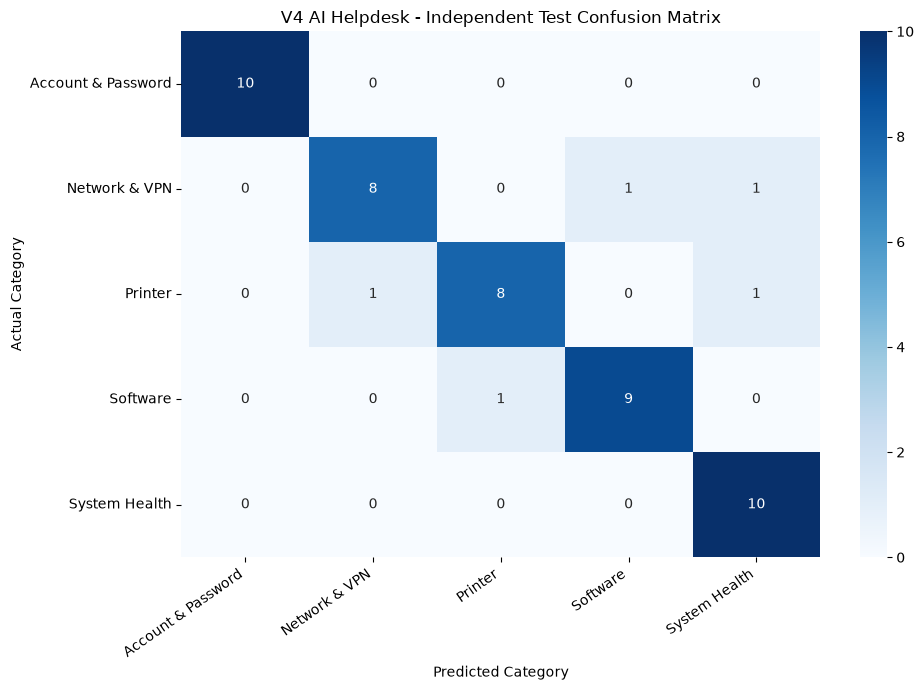

In [55]:
labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("V4 AI Helpdesk - Independent Test Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "v4_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Category-wise Accuracy and Error Analysis

In [56]:
predictions_df["Correct"] = (
    predictions_df["category"] ==
    predictions_df["V4_Prediction"]
)

category_accuracy = (
    predictions_df.groupby("category")["Correct"]
    .mean()
    .mul(100)
    .round(2)
    .reset_index(name="Accuracy_Percentage")
)

print("===== V4 CATEGORY-WISE ACCURACY =====")
display(category_accuracy)

incorrect_df = predictions_df[
    predictions_df["Correct"] == False
].copy()

incorrect_df["Error_Type"] = (
    incorrect_df["category"] +
    " -> " +
    incorrect_df["V4_Prediction"]
)

print("\n===== V4 INCORRECT PREDICTIONS =====")
display(
    incorrect_df[
        ["Test_ID", "user_query", "category",
         "V4_Prediction", "Confidence_Percentage"]
    ]
)

print("\n===== V4 ERROR SUMMARY =====")
display(
    incorrect_df["Error_Type"]
    .value_counts()
    .rename_axis("Error_Type")
    .reset_index(name="Error_Count")
)

incorrect_df.to_csv(
    RESULTS_DIR / "v4_classification_errors.csv",
    index=False
)

print("\nV4 error analysis saved successfully.")

===== V4 CATEGORY-WISE ACCURACY =====


,category,Accuracy_Percentage
0,Account & Password,100.0
1,Network & VPN,80.0
2,Printer,80.0
3,Software,90.0
4,System Health,100.0



===== V4 INCORRECT PREDICTIONS =====


,Test_ID,user_query,category,V4_Prediction,Confidence_Percentage
17,EXT018,My computer is receiving an invalid IP address.,Network & VPN,System Health,43.93
19,EXT020,I am getting a DNS server not responding error.,Network & VPN,Software,54.99
25,EXT026,My computer cannot communicate with the networ...,Printer,Network & VPN,62.85
27,EXT028,Print jobs are taking too long to complete.,Printer,System Health,64.72
39,EXT040,The program reports that it has stopped working.,Software,Printer,33.71



===== V4 ERROR SUMMARY =====


,Error_Type,Error_Count
0,Network & VPN -> System Health,1
1,Network & VPN -> Software,1
2,Printer -> Network & VPN,1
3,Printer -> System Health,1
4,Software -> Printer,1



V4 error analysis saved successfully.


In [ ]:
# V3 vs V4 Final Model Comparison

In [57]:
import pandas as pd
import joblib
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
MODEL_DIR = BASE_DIR / "models"
DATA_DIR = BASE_DIR / "dataset" / "processed"
RESULTS_DIR = BASE_DIR / "results"

RESULTS_DIR.mkdir(exist_ok=True)

V3_PATH = MODEL_DIR / "it_helpdesk_classifier_v3.pkl"
V4_PATH = MODEL_DIR / "it_helpdesk_classifier_v4.pkl"

TEST_PATH = DATA_DIR / "expanded_classification_test_template.csv"

# Load models and independent test data
v3_model = joblib.load(V3_PATH)
v4_model = joblib.load(V4_PATH)

test_df = pd.read_csv(TEST_PATH)

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"].astype(str)

# Predictions
v3_pred = v3_model.predict(X_test)
v4_pred = v4_model.predict(X_test)

# Evaluation function
def evaluate_model(model_name, y_true, predictions):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro_Precision": precision_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),
        "Macro_Recall": recall_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),
        "Macro_F1": f1_score(
            y_true, predictions,
            average="macro", zero_division=0
        ),
        "Correct_Predictions": int(
            (y_true == predictions).sum()
        ),
        "Incorrect_Predictions": int(
            (y_true != predictions).sum()
        )
    }

comparison_df = pd.DataFrame([
    evaluate_model("V3 - Previous Model", y_test, v3_pred),
    evaluate_model("V4 - Leakage-Free Model", y_test, v4_pred)
])

print("===== V3 vs V4 FINAL COMPARISON =====")
display(comparison_df.round(4))

comparison_path = RESULTS_DIR / "v3_v4_final_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("Comparison saved:", comparison_path)

===== V3 vs V4 FINAL COMPARISON =====


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Correct_Predictions,Incorrect_Predictions
0,V3 - Previous Model,0.9,0.9022,0.9,0.8987,45,5
1,V4 - Leakage-Free Model,0.9,0.9022,0.9,0.8987,45,5


Comparison saved: D:\AI_IT_HELPDESK\results\v3_v4_final_comparison.csv


In [ ]:
# Prediction changes between models

In [58]:
comparison_predictions = test_df.copy()

comparison_predictions["V3_Prediction"] = v3_pred
comparison_predictions["V4_Prediction"] = v4_pred

comparison_predictions["V3_Correct"] = (
    comparison_predictions["category"] ==
    comparison_predictions["V3_Prediction"]
)

comparison_predictions["V4_Correct"] = (
    comparison_predictions["category"] ==
    comparison_predictions["V4_Prediction"]
)

corrected_by_v4 = comparison_predictions[
    (~comparison_predictions["V3_Correct"]) &
    (comparison_predictions["V4_Correct"])
]

new_errors_v4 = comparison_predictions[
    (comparison_predictions["V3_Correct"]) &
    (~comparison_predictions["V4_Correct"])
]

same_errors = comparison_predictions[
    (~comparison_predictions["V3_Correct"]) &
    (~comparison_predictions["V4_Correct"])
]

print("===== PREDICTION CHANGE ANALYSIS =====")
print("Corrected by V4:", len(corrected_by_v4))
print("New errors introduced by V4:", len(new_errors_v4))
print("Incorrect in both models:", len(same_errors))

print("\n===== CORRECTED BY V4 =====")
display(corrected_by_v4)

print("\n===== NEW V4 ERRORS =====")
display(new_errors_v4)

print("\n===== ERRORS IN BOTH MODELS =====")
display(same_errors)

comparison_predictions.to_csv(
    RESULTS_DIR / "v3_v4_prediction_comparison.csv",
    index=False
)

print("\nPrediction comparison saved successfully.")

===== PREDICTION CHANGE ANALYSIS =====
Corrected by V4: 0
New errors introduced by V4: 0
Incorrect in both models: 5

===== CORRECTED BY V4 =====


,Test_ID,user_query,category,V3_Prediction,V4_Prediction,V3_Correct,V4_Correct



===== NEW V4 ERRORS =====


,Test_ID,user_query,category,V3_Prediction,V4_Prediction,V3_Correct,V4_Correct



===== ERRORS IN BOTH MODELS =====


,Test_ID,user_query,category,V3_Prediction,V4_Prediction,V3_Correct,V4_Correct
17,EXT018,My computer is receiving an invalid IP address.,Network & VPN,System Health,System Health,False,False
19,EXT020,I am getting a DNS server not responding error.,Network & VPN,Software,Software,False,False
25,EXT026,My computer cannot communicate with the networ...,Printer,Network & VPN,Network & VPN,False,False
27,EXT028,Print jobs are taking too long to complete.,Printer,System Health,System Health,False,False
39,EXT040,The program reports that it has stopped working.,Software,Printer,Printer,False,False



Prediction comparison saved successfully.


In [ ]:
# Confidence analysis

In [59]:
import pandas as pd
import numpy as np
import joblib

from pathlib import Path
from sklearn.metrics import accuracy_score

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v4.pkl"
TEST_PATH = BASE_DIR / "dataset" / "processed" / "expanded_classification_test_template.csv"
RESULTS_DIR = BASE_DIR / "results"

RESULTS_DIR.mkdir(exist_ok=True)

model = joblib.load(MODEL_PATH)
test_df = pd.read_csv(TEST_PATH)

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"].astype(str)

predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)

test_df["Predicted_Category"] = predictions
test_df["Confidence_Percentage"] = (
    probabilities.max(axis=1) * 100
).round(2)

test_df["Correct"] = (
    test_df["category"] == test_df["Predicted_Category"]
)

print("===== V4 CONFIDENCE SUMMARY =====")
print("Average confidence:", round(
    test_df["Confidence_Percentage"].mean(), 2
))
print("Minimum confidence:", round(
    test_df["Confidence_Percentage"].min(), 2
))
print("Maximum confidence:", round(
    test_df["Confidence_Percentage"].max(), 2
))

display(test_df[
    ["Test_ID", "user_query", "category",
     "Predicted_Category", "Confidence_Percentage", "Correct"]
])

test_df.to_csv(
    RESULTS_DIR / "v4_confidence_predictions.csv",
    index=False
)

===== V4 CONFIDENCE SUMMARY =====
Average confidence: 79.3
Minimum confidence: 33.71
Maximum confidence: 95.32


,Test_ID,user_query,category,Predicted_Category,Confidence_Percentage,Correct
0,EXT001,I cannot remember my Windows login password.,Account & Password,Account & Password,91.73,True
1,EXT002,My domain account says the password has expired.,Account & Password,Account & Password,91.08,True
2,EXT003,My account is locked after several failed logi...,Account & Password,Account & Password,89.75,True
3,EXT004,I cannot sign in to my computer using my domai...,Account & Password,Account & Password,88.58,True
4,EXT005,How can I change my current Windows password?,Account & Password,Account & Password,83.57,True
5,EXT006,My username and password are not being accepted.,Account & Password,Account & Password,84.88,True
6,EXT007,I need assistance resetting my Microsoft 365 p...,Account & Password,Account & Password,83.60,True
7,EXT008,My account has been disabled and I cannot log in.,Account & Password,Account & Password,90.29,True
8,EXT009,I can log in to Windows but cannot access my w...,Account & Password,Account & Password,87.72,True
9,EXT010,I am getting an authentication error when sign...,Account & Password,Account & Password,49.58,True


In [ ]:
# Threshold comparison

In [60]:
threshold_results = []

for threshold in [60, 70, 80]:
    accepted = test_df[
        test_df["Confidence_Percentage"] >= threshold
    ]

    review = test_df[
        test_df["Confidence_Percentage"] < threshold
    ]

    accepted_accuracy = (
        accuracy_score(
            accepted["category"],
            accepted["Predicted_Category"]
        ) * 100
        if len(accepted) > 0 else 0
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accepted_Predictions": len(accepted),
        "Sent_For_Review": len(review),
        "Coverage_Percentage": round(
            len(accepted) / len(test_df) * 100, 2
        ),
        "Accuracy_Of_Accepted": round(
            accepted_accuracy, 2
        ),
        "Errors_Among_Accepted": int(
            (~accepted["Correct"]).sum()
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("===== V4 CONFIDENCE THRESHOLD COMPARISON =====")
display(threshold_df)

threshold_df.to_csv(
    RESULTS_DIR / "v4_confidence_threshold_analysis.csv",
    index=False
)

print("Threshold analysis saved successfully.")

===== V4 CONFIDENCE THRESHOLD COMPARISON =====


,Threshold,Accepted_Predictions,Sent_For_Review,Coverage_Percentage,Accuracy_Of_Accepted,Errors_Among_Accepted
0,60,44,6,88.0,95.45,2
1,70,38,12,76.0,100.00,0
2,80,32,18,64.0,100.00,0


Threshold analysis saved successfully.


In [ ]:
# Human review queue

In [61]:
review_queue = test_df[
    test_df["Confidence_Percentage"] < 70
].copy()

review_queue["Review_Status"] = "HUMAN_REVIEW_REQUIRED"

print("===== V4 HUMAN REVIEW QUEUE =====")
print("Total test records:", len(test_df))
print("Human review required:", len(review_queue))
print("Automatically accepted:", len(test_df) - len(review_queue))

display(review_queue[
    ["Test_ID", "user_query", "Predicted_Category",
     "Confidence_Percentage", "category", "Review_Status"]
])

review_queue.to_csv(
    RESULTS_DIR / "v4_human_review_queue.csv",
    index=False
)

print("Human review queue saved successfully.")

===== V4 HUMAN REVIEW QUEUE =====
Total test records: 50
Human review required: 12
Automatically accepted: 38


,Test_ID,user_query,Predicted_Category,Confidence_Percentage,category,Review_Status
9,EXT010,I am getting an authentication error when sign...,Account & Password,49.58,Account & Password,HUMAN_REVIEW_REQUIRED
10,EXT011,My computer is connected to WiFi but websites ...,Network & VPN,49.01,Network & VPN,HUMAN_REVIEW_REQUIRED
17,EXT018,My computer is receiving an invalid IP address.,System Health,43.93,Network & VPN,HUMAN_REVIEW_REQUIRED
19,EXT020,I am getting a DNS server not responding error.,Software,54.99,Network & VPN,HUMAN_REVIEW_REQUIRED
25,EXT026,My computer cannot communicate with the networ...,Network & VPN,62.85,Printer,HUMAN_REVIEW_REQUIRED
27,EXT028,Print jobs are taking too long to complete.,System Health,64.72,Printer,HUMAN_REVIEW_REQUIRED
28,EXT029,I cannot print PDF documents from my computer.,Printer,66.60,Printer,HUMAN_REVIEW_REQUIRED
30,EXT031,Microsoft Excel closes unexpectedly when I ope...,Software,66.45,Software,HUMAN_REVIEW_REQUIRED
33,EXT034,Microsoft Outlook is not opening on my computer.,Software,65.70,Software,HUMAN_REVIEW_REQUIRED
36,EXT037,My browser crashes when accessing the internal...,Software,59.32,Software,HUMAN_REVIEW_REQUIRED


Human review queue saved successfully.


In [ ]:
# Prepare Streamlit App for V4 Model Integration-Check current model references

In [62]:
from pathlib import Path

APP_PATH = Path(r"D:\AI_IT_HELPDESK\frontend\app.py")
V4_MODEL_PATH = Path(r"D:\AI_IT_HELPDESK\models\it_helpdesk_classifier_v4.pkl")

print("App exists:", APP_PATH.exists())
print("V4 model exists:", V4_MODEL_PATH.exists())

app_text = APP_PATH.read_text(encoding="utf-8")

print("\n===== MODEL REFERENCES IN APP.PY =====")

for line_no, line in enumerate(app_text.splitlines(), start=1):
    if "MODEL_PATH" in line or "it_helpdesk_classifier" in line:
        print(f"Line {line_no}: {line.strip()}")

App exists: True
V4 model exists: True

===== MODEL REFERENCES IN APP.PY =====
Line 20: MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v3.pkl"
Line 630: classifier = joblib.load(MODEL_PATH)


In [ ]:
# Test V4 model independently

In [63]:
import joblib

model = joblib.load(V4_MODEL_PATH)

sample_queries = [
    "My office printer is offline.",
    "I cannot connect to the company VPN.",
    "My Windows password has expired.",
    "Microsoft Excel is crashing.",
    "My computer is running very slowly."
]

predictions = model.predict(sample_queries)
probabilities = model.predict_proba(sample_queries)

import pandas as pd

v4_test_results = pd.DataFrame({
    "User_Query": sample_queries,
    "Predicted_Category": predictions,
    "Confidence_Percentage": (
        probabilities.max(axis=1) * 100
    ).round(2)
})

display(v4_test_results)

,User_Query,Predicted_Category,Confidence_Percentage
0,My office printer is offline.,Printer,91.02
1,I cannot connect to the company VPN.,Network & VPN,91.54
2,My Windows password has expired.,Account & Password,80.15
3,Microsoft Excel is crashing.,Software,71.73
4,My computer is running very slowly.,System Health,89.92


In [ ]:
# Update Streamlit to V4 Model

In [64]:
from pathlib import Path
from datetime import datetime
import shutil

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
APP_PATH = BASE_DIR / "frontend" / "app.py"
BACKUP_DIR = BASE_DIR / "frontend" / "backups"

BACKUP_DIR.mkdir(parents=True, exist_ok=True)

# Create backup
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup_path = BACKUP_DIR / f"app_before_v4_{timestamp}.py"

shutil.copy2(APP_PATH, backup_path)

print("Backup completed:", backup_path)

# Read current app
app_text = APP_PATH.read_text(encoding="utf-8")

old_reference = (
    'MODEL_PATH = BASE_DIR / "models" / '
    '"it_helpdesk_classifier_v3.pkl"'
)

new_reference = (
    'MODEL_PATH = BASE_DIR / "models" / '
    '"it_helpdesk_classifier_v4.pkl"'
)

# Confirm expected reference exists exactly once
count = app_text.count(old_reference)

if count != 1:
    print("UPDATE CANCELLED")
    print("Expected one V3 reference, found:", count)
    print("No changes were made.")
else:
    updated_text = app_text.replace(
        old_reference,
        new_reference,
        1
    )

    APP_PATH.write_text(
        updated_text,
        encoding="utf-8"
    )

    print("V4 model reference updated successfully.")

Backup completed: D:\AI_IT_HELPDESK\frontend\backups\app_before_v4_20261104_104835.py
V4 model reference updated successfully.


In [ ]:
# Verify updated model reference

In [65]:
app_text = APP_PATH.read_text(encoding="utf-8")

print("===== MODEL REFERENCE VERIFICATION =====")

for line_no, line in enumerate(app_text.splitlines(), start=1):
    if "MODEL_PATH" in line or "it_helpdesk_classifier" in line:
        print(f"Line {line_no}: {line.strip()}")

print("\nV4 reference exists:",
      "it_helpdesk_classifier_v4.pkl" in app_text)

print("V3 reference exists:",
      "it_helpdesk_classifier_v3.pkl" in app_text)

===== MODEL REFERENCE VERIFICATION =====
Line 20: MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v4.pkl"
Line 630: classifier = joblib.load(MODEL_PATH)

V4 reference exists: True
V3 reference exists: False


In [ ]:
# Restart Streamlit

In [66]:
import subprocess
import sys

APP_PATH = Path(
    r"D:\AI_IT_HELPDESK\frontend\app.py"
)

process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        str(APP_PATH),
        "--server.port=8501"
    ],
    cwd=str(APP_PATH.parent)
)

print("Streamlit restarted.")
print("Open: http://localhost:8501")

Streamlit restarted.
Open: http://localhost:8501


In [ ]:
# Compare V4 model confidence

In [67]:
import joblib
import numpy as np
from pathlib import Path

MODEL_PATH = Path(
    r"D:\AI_IT_HELPDESK\models\it_helpdesk_classifier_v4.pkl"
)

model = joblib.load(MODEL_PATH)

test_queries = [
    "My office printer is offline",
    "I cannot connect to the company VPN.",
    "My Windows password has expired.",
    "Microsoft Excel is crashing.",
    "My computer is running very slowly."
]

predictions = model.predict(test_queries)
probabilities = model.predict_proba(test_queries)

print("MODEL:", type(model))
print("CLASSES:", model.classes_)

for query, prediction, probs in zip(
    test_queries, predictions, probabilities
):
    print("\nQuery:", query)
    print("Prediction:", prediction)
    print("Maximum probability:", round(float(np.max(probs)) * 100, 2))
    print("Probability sum:", round(float(np.sum(probs)), 4))
    print("All probabilities:", np.round(probs, 4))

MODEL: <class 'sklearn.pipeline.Pipeline'>
CLASSES: ['Account & Password' 'Network & VPN' 'Printer' 'Software' 'System Health']

Query: My office printer is offline
Prediction: Printer
Maximum probability: 91.02
Probability sum: 1.0
All probabilities: [0.0328 0.0351 0.9102 0.0104 0.0116]

Query: I cannot connect to the company VPN.
Prediction: Network & VPN
Maximum probability: 91.54
Probability sum: 1.0
All probabilities: [0.0218 0.9154 0.0243 0.0322 0.0064]

Query: My Windows password has expired.
Prediction: Account & Password
Maximum probability: 80.15
Probability sum: 1.0
All probabilities: [0.8015 0.0082 0.0369 0.0142 0.1393]

Query: Microsoft Excel is crashing.
Prediction: Software
Maximum probability: 71.73
Probability sum: 1.0
All probabilities: [0.0722 0.049  0.0827 0.7173 0.0788]

Query: My computer is running very slowly.
Prediction: System Health
Maximum probability: 89.92
Probability sum: 1.0
All probabilities: [0.0273 0.0269 0.0295 0.0172 0.8992]


In [68]:
import subprocess
import sys
from pathlib import Path

APP_PATH = Path(r"D:\AI_IT_HELPDESK\frontend\app.py")

# Clear Streamlit cache
subprocess.run(
    [sys.executable, "-m", "streamlit", "cache", "clear"],
    check=False
)

# Restart application
process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        str(APP_PATH),
        "--server.port=8501"
    ],
    cwd=str(APP_PATH.parent)
)

print("Application started: http://localhost:8501")


Application started: http://localhost:8501


In [ ]:
# Create feedback export function

In [69]:

import sqlite3
import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
DB_PATH = BASE_DIR / "database" / "helpdesk.db"

conn = sqlite3.connect(DB_PATH)

feedback_df = pd.read_sql_query("""
    SELECT
        prediction_id,
        user_query,
        predicted_category,
        confidence,
        reviewed_category,
        reviewed_by,
        reviewed_at
    FROM ai_predictions
    WHERE review_status = 'Reviewed'
      AND reviewed_category IS NOT NULL
    ORDER BY prediction_id
""", conn)

conn.close()

print("===== HUMAN REVIEW FEEDBACK =====")
print("Reviewed records:", len(feedback_df))

if not feedback_df.empty:
    display(feedback_df)
else:
    print("No reviewed records available.")


===== HUMAN REVIEW FEEDBACK =====
Reviewed records: 1


,prediction_id,user_query,predicted_category,confidence,reviewed_category,reviewed_by,reviewed_at
0,2,monitor not working,Software,0.230456,Software,1,2026-11-04 04:43:18


In [70]:
import subprocess
import sys
from pathlib import Path

APP_PATH = Path(r"D:\AI_IT_HELPDESK\frontend\app.py")

process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        str(APP_PATH),
        "--server.port=8501"
    ],
    cwd=str(APP_PATH.parent)
)

print("Application URL: http://localhost:8501")

Application URL: http://localhost:8501


In [ ]:
# Review Feedback Accuracy

In [71]:
import sqlite3
import pandas as pd
from pathlib import Path

DB_PATH = Path(r"D:\AI_IT_HELPDESK\database\helpdesk.db")

conn = sqlite3.connect(DB_PATH)

feedback_df = pd.read_sql_query("""
    SELECT
        prediction_id,
        user_query,
        predicted_category,
        reviewed_category,
        confidence,
        review_status,
        reviewed_at
    FROM ai_predictions
    WHERE review_status = 'Reviewed'
    ORDER BY prediction_id
""", conn)

conn.close()

feedback_df["prediction_correct"] = (
    feedback_df["predicted_category"]
    == feedback_df["reviewed_category"]
)

display(feedback_df)

print("Total reviewed records:", len(feedback_df))

if len(feedback_df) > 0:
    print(
        "Human review agreement:",
        round(feedback_df["prediction_correct"].mean() * 100, 2),
        "%"
    )

,prediction_id,user_query,predicted_category,reviewed_category,confidence,review_status,reviewed_at,prediction_correct
0,2,monitor not working,Software,Software,0.230456,Reviewed,2026-11-04 04:43:18,True


Total reviewed records: 1
Human review agreement: 100.0 %


In [ ]:
# Check whether feedback is already in the training dataset – Training Dataset Verification

In [72]:
import pandas as pd
from pathlib import Path
import re

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

TRAIN_PATH = BASE_DIR / "dataset" / "processed" / "training_dataset_v5_leakage_free.csv"
TEST_PATH = BASE_DIR / "dataset" / "processed" / "expanded_classification_test_template.csv"
FEEDBACK_PATH = BASE_DIR / "dataset" / "processed" / "human_review_feedback.csv"

def normalize_query(value):
    value = str(value).lower().strip()
    value = re.sub(r"[^\w\s]", "", value)
    value = re.sub(r"\s+", " ", value)
    return value

# Load training dataset
train_df = pd.read_csv(TRAIN_PATH)

# Load human-reviewed feedback
feedback_df = pd.read_csv(FEEDBACK_PATH)

query = "monitor not working"
normalized_query = normalize_query(query)

train_df["normalized_query"] = train_df["user_query"].apply(normalize_query)
feedback_df["normalized_query"] = feedback_df["user_query"].apply(normalize_query)

training_match = train_df[
    train_df["normalized_query"] == normalized_query
]

feedback_match = feedback_df[
    feedback_df["normalized_query"] == normalized_query
]

print("===== FEEDBACK TRAINING VERIFICATION =====")
print("Training records:", len(train_df))
print("Feedback records:", len(feedback_df))
print("Query:", query)

print("\nExisting training matches:", len(training_match))
print("Feedback matches:", len(feedback_match))

if not training_match.empty:
    print("\nExisting training record:")
    display(training_match[["user_query", "category"]])

if not feedback_match.empty:
    print("\nHuman-reviewed record:")
    display(feedback_match[["user_query", "category"]])

if not training_match.empty:
    print("\nRESULT: Record already exists in training data.")
    print("Do not add it again.")
else:
    print("\nRESULT: Record is not currently in this training dataset.")
    print("It may be eligible for a controlled training-data update.")


===== FEEDBACK TRAINING VERIFICATION =====
Training records: 162
Feedback records: 1
Query: monitor not working

Existing training matches: 1
Feedback matches: 1

Existing training record:


,user_query,category
161,monitor not working,Software



Human-reviewed record:


,user_query,category
0,monitor not working,Software



RESULT: Record already exists in training data.
Do not add it again.


In [ ]:
# Human Feedback Integration Summary

In [73]:
import pandas as pd
from pathlib import Path
from datetime import datetime

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")
RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

report = pd.DataFrame([{
    "evaluation_date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "training_records": len(train_df),
    "human_feedback_records": len(feedback_df),
    "existing_training_matches": len(training_match),
    "feedback_matches": len(feedback_match),
    "new_records_eligible": 0 if len(training_match) > 0 else 1,
    "duplicate_prevention": "PASSED",
    "integration_status": "NO NEW RECORD REQUIRED"
}])

report_path = RESULTS_DIR / "human_feedback_integration_report.csv"
report.to_csv(report_path, index=False)

display(report)

print("\nFeedback integration report saved:")
print(report_path)


,evaluation_date,training_records,human_feedback_records,existing_training_matches,feedback_matches,new_records_eligible,duplicate_prevention,integration_status
0,2026-11-04 11:27:35,162,1,1,1,0,PASSED,NO NEW RECORD REQUIRED



Feedback integration report saved:
D:\AI_IT_HELPDESK\results\human_feedback_integration_report.csv


In [ ]:
# Advanced AI Model Evaluation– Independent Test Evaluation

In [74]:
import joblib
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

MODEL_PATH = BASE_DIR / "models" / "it_helpdesk_classifier_v4.pkl"
TEST_PATH = BASE_DIR / "dataset" / "processed" / "expanded_classification_test_template.csv"

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Load V4 model and independent test data
model = joblib.load(MODEL_PATH)
test_df = pd.read_csv(TEST_PATH)

X_test = test_df["user_query"].astype(str)
y_test = test_df["category"].astype(str)

# Predict
y_pred = model.predict(X_test)

# Calculate metrics
metrics = {
    "Model": "V4 - Leakage-Free Model",
    "Test_Records": len(test_df),
    "Accuracy": accuracy_score(y_test, y_pred),
    "Macro_Precision": precision_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Macro_Recall": recall_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Macro_F1": f1_score(
        y_test, y_pred, average="macro", zero_division=0
    ),
    "Balanced_Accuracy": balanced_accuracy_score(y_test, y_pred),
    "MCC": matthews_corrcoef(y_test, y_pred)
}

print("===== V4 ADVANCED MODEL EVALUATION =====")

for key, value in metrics.items():
    if isinstance(value, (float, np.floating)):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("\n===== CLASSIFICATION REPORT =====")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# Save metrics
metrics_df = pd.DataFrame([metrics])

metrics_path = RESULTS_DIR / "v4_advanced_evaluation_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

# Save confusion matrix
labels = sorted(set(y_test) | set(y_pred))

cm = confusion_matrix(y_test, y_pred, labels=labels)

cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

cm_path = RESULTS_DIR / "v4_advanced_confusion_matrix.csv"
cm_df.to_csv(cm_path)

print("\nEvaluation metrics saved:", metrics_path)
print("Confusion matrix saved:", cm_path)

display(metrics_df)
display(cm_df)


===== V4 ADVANCED MODEL EVALUATION =====
Model: V4 - Leakage-Free Model
Test_Records: 50
Accuracy: 0.9000
Macro_Precision: 0.9022
Macro_Recall: 0.9000
Macro_F1: 0.8987
Balanced_Accuracy: 0.9000
MCC: 0.8763

===== CLASSIFICATION REPORT =====
                    precision    recall  f1-score   support

Account & Password       1.00      1.00      1.00        10
     Network & VPN       0.89      0.80      0.84        10
           Printer       0.89      0.80      0.84        10
          Software       0.90      0.90      0.90        10
     System Health       0.83      1.00      0.91        10

          accuracy                           0.90        50
         macro avg       0.90      0.90      0.90        50
      weighted avg       0.90      0.90      0.90        50


Evaluation metrics saved: D:\AI_IT_HELPDESK\results\v4_advanced_evaluation_metrics.csv
Confusion matrix saved: D:\AI_IT_HELPDESK\results\v4_advanced_confusion_matrix.csv


,Model,Test_Records,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Balanced_Accuracy,MCC
0,V4 - Leakage-Free Model,50,0.9,0.902222,0.9,0.89866,0.9,0.876315


,Account & Password,Network & VPN,Printer,Software,System Health
Account & Password,10,0,0,0,0
Network & VPN,0,8,0,1,1
Printer,0,1,8,0,1
Software,0,0,1,9,0
System Health,0,0,0,0,10


In [ ]:
# Error Analysis

In [75]:

import pandas as pd
from pathlib import Path

BASE_DIR = Path(r"D:\AI_IT_HELPDESK")

TEST_PATH = (
    BASE_DIR / "dataset" / "processed"
    / "expanded_classification_test_template.csv"
)

RESULTS_DIR = BASE_DIR / "results"

test_df = pd.read_csv(TEST_PATH).copy()

test_df["actual_category"] = test_df["category"].astype(str)
test_df["predicted_category"] = pd.Series(y_pred).astype(str)

test_df["correct"] = (
    test_df["actual_category"] == test_df["predicted_category"]
)

# Extract incorrect predictions
errors_df = test_df[~test_df["correct"]].copy()

errors_df["error_type"] = (
    errors_df["actual_category"]
    + " -> "
    + errors_df["predicted_category"]
)

print("===== V4 ERROR ANALYSIS =====")
print("Total test records:", len(test_df))
print("Correct predictions:", int(test_df["correct"].sum()))
print("Incorrect predictions:", len(errors_df))

print("\n===== INCORRECT PREDICTIONS =====")

display(errors_df[
    ["Test_ID", "user_query",
     "actual_category", "predicted_category", "error_type"]
])

# Error count by category
print("\n===== ERROR DISTRIBUTION =====")

error_summary = (
    errors_df["error_type"]
    .value_counts()
    .rename_axis("Error_Type")
    .reset_index(name="Error_Count")
)

display(error_summary)

# Save error analysis
error_path = RESULTS_DIR / "v4_detailed_error_analysis.csv"
errors_df.to_csv(error_path, index=False)

summary_path = RESULTS_DIR / "v4_error_distribution.csv"
error_summary.to_csv(summary_path, index=False)

print("\nError analysis saved:", error_path)
print("Error distribution saved:", summary_path)


===== V4 ERROR ANALYSIS =====
Total test records: 50
Correct predictions: 45
Incorrect predictions: 5

===== INCORRECT PREDICTIONS =====


,Test_ID,user_query,actual_category,predicted_category,error_type
17,EXT018,My computer is receiving an invalid IP address.,Network & VPN,System Health,Network & VPN -> System Health
19,EXT020,I am getting a DNS server not responding error.,Network & VPN,Software,Network & VPN -> Software
25,EXT026,My computer cannot communicate with the networ...,Printer,Network & VPN,Printer -> Network & VPN
27,EXT028,Print jobs are taking too long to complete.,Printer,System Health,Printer -> System Health
39,EXT040,The program reports that it has stopped working.,Software,Printer,Software -> Printer



===== ERROR DISTRIBUTION =====


,Error_Type,Error_Count
0,Network & VPN -> System Health,1
1,Network & VPN -> Software,1
2,Printer -> Network & VPN,1
3,Printer -> System Health,1
4,Software -> Printer,1



Error analysis saved: D:\AI_IT_HELPDESK\results\v4_detailed_error_analysis.csv
Error distribution saved: D:\AI_IT_HELPDESK\results\v4_error_distribution.csv
